# Fast Generation of Metrologically Relevant Fock State Mixtures: paper figures

This notebook generates **every figure** of the paper

> G. Reina Rivero, M. Morillas-Rozas, A. López-García and J. Cerrillo,
> *Fast Generation of Metrologically Relevant Fock State Mixtures*

and prints every number the text quotes from these simulations. It also draws three additional figures (S1–S3) that are not in the paper but support statements of its text. Results not shown in a figure (dephasing, end kick, radial modes, field geometry, cycle-period resonance) are in `supplementary_checks.ipynb`.

The notebook reads top to bottom: parameters, physical model, then one section per figure. Each section explains what is computed, then runs it, then draws the figure. The printed lines under each figure are the numbers quoted in the text.

## The protocol in one paragraph

A trapped ion has a spin (qubit, $|{\uparrow}\rangle,|{\downarrow}\rangle$) and one motional mode of frequency $\nu$. Starting from a Doppler-cooled thermal state, the **resonant sequence** repeats $R=80$ cycles of

$$Y(\pi/2)\;\to\;X(f\tau)\;\to\;Y(-\pi/2)\;\to\;\text{spin reset }\mathcal L_\Gamma\;\to\;\text{free evolution }t_d .$$

- **$X$ pulse.** A resonant carrier drive with Rabi frequency $\Omega=\nu$, of length $\tau=2\pi/(\eta\Omega\sqrt{n_0})$, or $f\tau$ once calibrated. Here $\eta$ is the Lamb–Dicke parameter.
- **$Y$ pulses.** Short pulses that rotate $|{\downarrow}\rangle$ into the dressed state $|-\rangle$ of the $X$ drive and back.
- **Spin reset.** Optical pumping to $|{\downarrow}\rangle$, with the recoil of the emitted photon.
- **Inter-cycle delay $t_d$.** A free evolution, zero in the nominal sequence.

At $\Omega=\nu$ the $X$ pulse couples $|-,n\rangle\leftrightarrow|+,n-1\rangle$ resonantly with a strength $\propto\eta\sqrt n$. A pulse of length $\tau$ makes a whole number of Rabi turns only for $n=n_0m^2$, so those levels are dark. Population on every other level is moved down by the reset, one level per cycle, until it reaches a dark level. The motion therefore converges to the **Fock-state mixture**
$$\rho_{\rm tr}=\sum_m p_{\rm tr}(m)\,|n_0m^2\rangle\langle n_0m^2|,\qquad p_{\rm tr}(m)=\sum_{n=n_0m^2}^{n_0(m+1)^2-1}p_{\rm th}(n).$$
The figure of merit is the trace distance $D=\tfrac12\sum_n|p_n-P^{\rm tr}_n|$ between the prepared Fock populations and this target.

**Units.** $\hbar=\nu=1$: times are in units of $1/\nu$ and frequencies in units of $\nu$. Conversions to physical units use $\nu=2\pi\times1$ MHz, and the $^{40}$Ca$^+$ model uses the corresponding Lamb–Dicke parameters.

## How to run it

| what | command | time |
|---|---|---|
| redraw everything from the shipped cache `figgen_cache.pkl` | *Run All* in Jupyter, or `jupyter nbconvert --to notebook --execute --inplace paper_figures.ipynb` | a few minutes |
| recompute from scratch (Linux, 32 cores) | delete `figgen_cache.pkl`, then `NPROC=32 jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 paper_figures.ipynb` | tens of CPU-hours |
| quick end-to-end code check | `SMOKE_TEST=1 jupyter nbconvert --to notebook --execute --output smoke.ipynb paper_figures.ipynb` | ~1 min |

- **Parallel runs.** Independent simulations run in `NPROC` worker processes, using the `fork` start method (Linux/macOS). On Windows the notebook runs serially.
- **Environment variables.** `NPROC` and `SMOKE_TEST` are read in the first code cell, so set them before the kernel starts, or assign `os.environ[...]` at the top of that cell.
- **Smoke test.** It uses $N=30$, $R=6$ and tiny grids, and keeps its cache and figures in a temporary folder.
- **Checkpointing.** Expensive results are checkpointed in `figgen_cache.pkl` (atomic writes every few minutes), so an interrupted run resumes where it stopped. Cache keys include the physical parameters ($k_BT$, $N$, $R$, $\Omega_Y$, $\Gamma$, the reset model, and every argument of a run).
- **If you change the physics** in a way the keys do not capture, for example by editing a Hamiltonian, delete the cache.

Figures are written to `figures/`.

| paper | file | section of this notebook |
|---|---|---|
| Fig. 1 | `figure_1.png` | Figure 1: concept |
| Fig. 2 | `figure_2.pdf` | Figure 2: final populations |
| Fig. 3 | `figure_3_plus_trace.pdf` | Figure 3: weak-driving SPT vs resonant sequence |
| Fig. 4 | `figure_preparation.pdf` | Figure 4: preparation from a Doppler-cooled ion |
| Fig. 5 | `figure_5.pdf` | Figure 5: timing calibration |
| Fig. 6 | `figure_6.pdf` | Figure 6: metrology |
| Fig. 7 | `figure_ca.pdf` | Figure 7: implementation in $^{40}$Ca$^+$ (last section; it reuses the results of S2 and S3) |
| not in the paper | `figure_S1_pulse_shaping.pdf` | Additional figure S1: pulse shaping (Sec. III B: shaping does not improve on the square pulse) |
| not in the paper | `figure_S2_tolerances.pdf` | Additional figure S2: tolerances and laser detuning (Sec. IV) |
| not in the paper | `figure_S3_implementation.pdf` | Additional figure S3: $^{40}$Ca$^+$ models in full (Sec. IV) |

## 1. Setup

The worker count is set before numpy is imported, so that each worker process uses one BLAS thread. `print` flushes immediately, so progress shows in server logs. Figures use the non-interactive Agg backend and the sizes of the manuscript (`0.45\textwidth`). `show()`, defined below, displays them here.

In [1]:
import os
import multiprocessing as mp

_FORK = "fork" in mp.get_all_start_methods()
NPROC = int(os.environ.get("NPROC", "0") or 0) or (os.cpu_count() or 1)
if not _FORK:
    NPROC = 1
if NPROC > 1:      # one BLAS thread per worker (must be set before numpy is imported)
    for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
        os.environ.setdefault(_v, "1")
SMOKE = bool(os.environ.get("SMOKE_TEST"))

import functools
import io
import pickle
import tempfile
import time
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from qutip import destroy, displace
from scipy.optimize import minimize_scalar
from IPython.display import Image, display

print = functools.partial(print, flush=True)     # progress is visible in server logs

## 2. Parameters

All quantities are in units of the trap frequency $\nu$.

- **Operating point.** The $X$ pulse is driven at $\Omega=\nu$ ($\Delta=0$). The trapped manifold is $n=n_0m^2$ with $n_0=1$.
- **Reference model of the pulses and reset**, used in all main figures. The $Y$ pulses are short ($\Omega_Y=100\nu$). The reset is a fast optical pumping ($\Gamma=1000\nu$) that lasts $20/\Gamma$, leaving a spin coherence of $e^{-10}$.
- **Initial state.** The Doppler-cooled thermal state $\rho_{\rm th}=e^{-\nu a^\dagger a/k_BT}/Z$ at the Doppler limit $k_BT=\hbar\Gamma_D/2$. With $\Gamma_D=22\nu$, the $S_{1/2}$–$P_{1/2}$ linewidth of $^{40}$Ca$^+$ at $\nu=2\pi\times1$ MHz, this gives $k_BT=11\nu$ and $\bar n\simeq10.5$.
- **Truncation.** We keep $N=100$ Fock levels; the thermal weight above $N$ is $10^{-4}$ (appendix of the paper).
- **Number of cycles.** $R=80$ in every figure.

In [2]:
# PARAMETERS (single source of truth; units of the trap frequency nu)
nu = 1.0                 # trap frequency
n0 = 1                   # trapped manifold n = n0 m^2
OMEGA = 1.0 * nu         # resonant operating point of the X pulse
OMEGA_Y = 100.0 * nu     # Y(pi/2) pulse strength (reference model: short pulses)
GAMMA = 1000.0 * nu      # spin-reset decay rate (reference model: fast reset)
T_RESET = 20.0 / GAMMA   # spin-reset duration (complete reset: coherence left e^-10)

# Initial state: Doppler-cooled thermal distribution. The Doppler limit is
# kT = hbar Gamma_D / 2, i.e. nbar ~ Gamma_D / (2 nu). Gamma_D = 22 nu is the
# 40Ca+ S1/2-P1/2 line (Gamma_D ~ 2 pi x 22 MHz) for a trap with nu = 2 pi x 1 MHz.
GAMMA_D = 22.0 * nu
KT = GAMMA_D / 2.0                          # = 11 nu
NBAR = 1.0 / np.expm1(nu / KT)              # = 10.5
NU_HZ = 1.0e6                               # nu / 2 pi in Hz, for the time axes and heating rates

# Fock-space truncation. Weight of the thermal state above level N is
# (nbar/(nbar+1))^N: 11% for N = 24, 7e-4 for N = 80, 1e-4 for N = 100.
N = 100
R = 80                   # pulse cycles per preparation (all figures; TD minimum at eta_ref)
ETA_REF = 0.05           # reference Lamb-Dicke parameter
RESET_NODES = 48         # Gauss-Legendre nodes for a fast reset (nu * T_reset <= 0.1)
RESET_NODES_SLOW = 120   # minimum nodes for a slow reset (converged: 120 and 300 nodes agree to 1e-5)

### Pulse and reset models

A model is a dictionary of six entries:

| key | meaning |
|---|---|
| `Oy` | $Y$-pulse Rabi frequency $\Omega_Y$ |
| `G`, `Tr` | effective decay rate $\Gamma$ of the reset and its duration |
| `em_rel` / `em_abs` | Lamb–Dicke parameter of the emitted photon, relative to $\eta$ or absolute |
| `abs_rel` | kick of the absorbed (quench) photon, relative to $\eta$ |
| `p_rep` | probability of one further absorption–emission cycle |

There are two kinds of model:
- **`ref`** (all main figures): $\Omega_Y=100\nu$, $\Gamma=1000\nu$, and emission recoil $\eta'=\eta$.
- **$^{40}$Ca$^+$** (Section IV of the paper). The qubit is $S_{1/2}(m=-1/2)\leftrightarrow D_{5/2}(m=-5/2)$ at 729 nm. The $X$ and $Y$ pulses are the same 729-nm beam with switched phase, at $\Omega_Y=2\nu$ (`Ca_Oy2`) or $\Omega_Y=\nu$ (`Ca_Oy1`). The reset is an 854-nm quench to $P_{3/2}$ followed by 393-nm decay: effective rate $\Gamma_{\rm eff}=3\nu$, 393-nm recoil $\eta'=0.18$ along the axis, an 854-nm kick of $0.854\eta$, and a 6.5% branching back to the $D$ levels. $\eta=\eta_{729}\cos\theta$ is set with the beam angle $\theta$; along the axis $\eta_{729}=0.097$.

In [3]:
# ---- reset/Y-pulse models ----------------------------------------------------------------------
# Oy: Y-pulse Rabi frequency; G: effective decay rate of the reset; Tr: reset duration;
# em_rel / em_abs: Lamb-Dicke parameter of the emitted photon (relative to eta, or absolute);
# abs_rel: deterministic kick of the absorbed (quench) photon, relative to eta;
# p_rep: probability of one further absorption-emission cycle (decay back to the D levels).
MODEL_REF = dict(Oy=OMEGA_Y, G=GAMMA, Tr=T_RESET, em_rel=1.0, em_abs=None, abs_rel=0.0, p_rep=0.0)

# 40Ca+ at nu = 2 pi x 1 MHz (referee M4). Qubit S1/2(m=-1/2) <-> D5/2(m=-5/2) at 729 nm; X and Y pulses
# are phase-switched 729-nm pulses; eta = eta_729 cos(theta) is tuned with the beam angle theta.
# Reset: 854-nm quench D5/2 -> P3/2(m=-3/2), decay at 393 nm to S1/2(m=-1/2) (sigma pattern, quantisation
# axis along the mode), with branching 6.5% back to D5/2/D3/2 (one further cycle). The 854-nm beam is
# assumed to have the same projection on the mode as the 729-nm beam (kick (729/854) eta).
_HBAR, _AMU = 1.054571817e-34, 1.66053907e-27
_X0 = np.sqrt(_HBAR / (2 * 39.9626 * _AMU * 2 * np.pi * NU_HZ))       # ground-state size, 11.2 nm
ETA_CA_AXIAL = 2 * np.pi / 729.147e-9 * _X0                           # 0.097: 729 nm along the mode
ETA_393 = 2 * np.pi / 393.366e-9 * _X0                                # 0.180: emitted 393-nm photon
CA_RESET = dict(G=3.0 * nu, Tr=20.0 / 3.0, em_rel=None, em_abs=round(float(ETA_393), 5),
                abs_rel=round(729.147 / 854.209, 5), p_rep=0.065)
MODELS = {
    "ref": MODEL_REF,
    "Ca_Oy2": dict(Oy=2.0 * nu, **CA_RESET),     # Y pulses at twice the X-pulse Rabi frequency
    "Ca_Oy1": dict(Oy=1.0 * nu, **CA_RESET),     # Y pulses = the X-pulse beam, phase-switched
}

### Scan grids of each figure

The common fine grid `ETA_FINE` ($\eta=0.02$–$0.2$ in steps of $0.005$) is shared by Figs. 3(B) and 5(B). Each figure reuses the calibrations of Fig. 5, so the grids are subsets of each other where possible.

In [4]:
# figure-specific grids
ETA_FINE = np.round(np.arange(0.02, 0.2001, 0.005), 4)     # common fine eta grid (Figs. 3B, 5A)
FIG2_ETAS = [0.01, 0.05, 0.1, 0.2]
FIG3_ETAS = [0.02, 0.05, 0.1, 0.2]
FIG3_OMEGAS = np.array([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 4.0, 8.0])
FIG3_ETA_SWEEP = np.concatenate([ETA_FINE, np.round(np.arange(0.21, 0.4001, 0.01), 4)])
FIG3_OMEGA_OLD = 0.001   # weak-driving SPT protocol in the eta sweep
FIG3_RECAL_ETAS = [0.02, 0.05, 0.1]               # weak-driving protocol with recalibrated pulse length
FIG3_RECAL_OMEGAS = [0.01, 0.001]
FIG3_RECAL_F = 1 + np.linspace(-0.05, 0.15, 41)
CONV_OMEGAS_OLD = [0.01, 0.001]
CONV_CYCLES = 200
DOPPLER_NBARS = np.array([0.1, 0.3, 0.5, 1, 2, 3, 5, 7, 10, 12.5, 15])
DOPPLER_ETAS = [0.02, 0.05, 0.1]
DOPPLER_CYCLES = 300
DOPPLER_BAND = (5.0, 20.0)               # typical Doppler limits nbar ~ Gamma_D/(2 nu)
# Timing calibration (referee M3): pulse length f tau and free evolution ("delay") after each reset.
# Stage 1: grid f = 1 + eta * CAL_F_REL x CAL_DELAYS; stage 2: local refinement around the best point.
CAL_F_REL = np.linspace(-0.4, 0.4, 17)                     # step 0.05 eta (counter-rotating period: eta/2)
CAL_DELAYS = 2 * np.pi * np.arange(16) / 16
CAL_REF_F = np.linspace(-0.04, 0.04, 9)                    # x eta
CAL_REF_D = np.linspace(-0.2, 0.2, 9)
FIG5_DOM_ETAS = [0.05, 0.1, 0.125, 0.15, 0.175, 0.2]       # Rabi-frequency offset on top of the timing
FIG5_DOM_SCAN = np.linspace(-0.08, 0.08, 17)
FIG5_DOM_F_REL = np.linspace(-0.04, 0.04, 5)
FIG5_MAP_ETA = ETA_REF
FIG5_MAP_F_REL = np.linspace(-0.2, 0.3, 26)                # f - 1 in units of eta
FIG5_MAP_DELAYS = 2 * np.pi * np.arange(36) / 36
FIG6_ETAS = [0.02, 0.05, 0.1, 0.15, 0.2]     # subset of ETA_FINE (reuses the calibration)
FIG6_ETA_SHOW = 0.05
FIG6_OMEGA_OLD = 0.01                        # weak-driving SPT protocol shown for comparison
FIG6_READOUT_CANDIDATES = [4, 9, 16]
FIG6_ALPHAS = np.linspace(1e-3, 1.2, 4801)   # uniform grid; panel A adds dense points around every dip
FIG6_FULLRHO_ETAS = [0.05, 0.1]              # Fisher information from the full state (referee M6d)
F_SQL = 4.0
FIG7_ETAS_SHAPE = [0.05, 0.075, 0.1, 0.125, 0.15, 0.175, 0.2]   # subset of ETA_FINE
FIG7_ETAS_CHIRP = [0.05, 0.1, 0.15, 0.2]
FIG7_AMPS = np.linspace(-0.2, 0.2, 17)
M_SHAPE, M_CHIRP = 50, 40                # time slices of shaped X pulses
M_SMOOTH = 400                           # time slices of the plateau and chirped envelopes
# relative calibration errors (referee M5): +-2% in steps of 0.25%, plus steps of 0.05% within +-0.4%,
# which resolve the narrow optimum of the calibrated timing
ROB_EPS = np.unique(np.round(np.concatenate([np.linspace(-0.02, 0.02, 17), np.linspace(-0.004, 0.004, 17)]), 6))
ROB_DELTAS = np.array([0.0, 0.01, 0.02, 0.05, 0.1, 0.2])
ROB_NOISE = [0.002, 0.005, 0.01]         # rms relative Rabi-frequency noise
ROB_HEAT = [1e0, 1e1, 1e2, 1e3, 1e4]     # motional heating rates, quanta per second
ETA_IMPL = [0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, round(float(ETA_CA_AXIAL), 4)]
IMPL_OY = [1.0, 2.0, 5.0, 10.0, 100.0]   # Y-pulse Rabi frequencies at eta_ref
IMPL_GAMMAS = [1.0, 10.0]                # further quench rates (Ca reset, Omega_Y = 2 nu)

### Paths, smoke test and cache tag

Figures go to `figures/` next to this notebook, and the cache is `figgen_cache.pkl`. The smoke test replaces every grid with a tiny one, and keeps its cache and figures in a temporary folder.

`TAG` holds the physical parameters that enter every cache key.

In [5]:
HERE = os.path.abspath("")                     # the folder of this notebook (Jupyter runs it there)
FIGDIR = os.path.join(HERE, "figures")
CACHEFILE = os.path.join(HERE, "figgen_cache.pkl")

if SMOKE:   # tiny version of every computation: checks the code end to end in a few minutes
    N, R = 30, 6
    ETA_FINE = np.array([0.05, 0.1])
    FIG2_ETAS = [0.05, 0.1, 0.15, 0.2]
    FIG3_ETAS = [0.05, 0.1]
    FIG3_OMEGAS = np.array([0.01, 1.0])
    FIG3_ETA_SWEEP = np.array([0.05, 0.1])
    FIG3_RECAL_ETAS, FIG3_RECAL_OMEGAS, FIG3_RECAL_F = [0.05], [0.01], np.array([1.0, 1.01])
    CONV_OMEGAS_OLD, CONV_CYCLES = [0.01], 10
    DOPPLER_NBARS, DOPPLER_ETAS, DOPPLER_CYCLES = np.array([1.0, 10.0]), [0.05], 10
    CAL_F_REL, CAL_DELAYS = np.array([-0.2, 0.0, 0.2]), np.array([0.0, np.pi])
    CAL_REF_F, CAL_REF_D = np.array([-0.02, 0.0, 0.02]), np.array([-0.1, 0.0, 0.1])
    FIG5_DOM_ETAS, FIG5_DOM_SCAN, FIG5_DOM_F_REL = [0.1], np.array([-0.04, 0.0, 0.04]), np.array([0.0])
    FIG5_MAP_F_REL, FIG5_MAP_DELAYS = np.array([-0.1, 0.0, 0.1]), np.array([0.0, 2.0, 4.0])
    FIG6_ETAS, FIG6_FULLRHO_ETAS = [0.05, 0.1], [0.05]
    FIG6_ALPHAS = np.linspace(1e-3, 1.2, 241)
    FIG7_ETAS_SHAPE = FIG7_ETAS_CHIRP = [0.05]
    FIG7_AMPS = np.array([-0.1, 0.1])
    M_SHAPE, M_CHIRP, M_SMOOTH = 10, 8, 40
    ROB_EPS, ROB_DELTAS, ROB_NOISE, ROB_HEAT = np.array([-0.01, 0.0, 0.01]), np.array([0.0, 0.05]), [0.01], [1e3]
    ETA_IMPL, IMPL_OY, IMPL_GAMMAS = [0.05], [2.0, 100.0], [10.0]
    RESET_NODES_SLOW = 30
    _SMOKE_DIR = os.path.join(tempfile.gettempdir(), "fock_figs_smoke")
    FIGDIR, CACHEFILE = _SMOKE_DIR, os.path.join(_SMOKE_DIR, "smoke_cache.pkl")
    print(f"SMOKE TEST: N={N}, R={R}, output and cache in {_SMOKE_DIR}")

os.makedirs(FIGDIR, exist_ok=True)
TAG = (f"kT={KT}", f"N={N}", f"R={R}", f"Oy={OMEGA_Y}", f"G={GAMMA}",
       f"reset=1ch,T={T_RESET * GAMMA:g}/G")

STYLE = {
    "text.usetex": False, "font.size": 11, "axes.labelsize": 11,
    "axes.titlesize": 11, "legend.fontsize": 9.5, "xtick.labelsize": 10,
    "ytick.labelsize": 10, "lines.linewidth": 1.4, "lines.markersize": 4,
    "figure.dpi": 200, "savefig.bbox": "tight",
}

## 3. Caching and parallel runs

- **`cached(key, fn)`** returns the stored value of `key`, or computes `fn()` and stores it.
- **`cached_map`** does the same for a list of runs. It computes the missing ones in parallel worker processes and saves the cache every 5 minutes.

Keys are tagged with `TAG`. Results of the resonant sequence are also tagged `Yinv=phaseflip`: $Y(-\pi/2)$ is the physical phase-flipped pulse, not the exact inverse of $Y(\pi/2)$.

In [6]:
# HELPERS
try:
    with open(CACHEFILE, "rb") as fh:
        _CACHE = pickle.load(fh)
except Exception:
    _CACHE = {}


def _save_cache():
    tmp = CACHEFILE + ".tmp"
    with open(tmp, "wb") as fh:
        pickle.dump(_CACHE, fh)
    os.replace(tmp, CACHEFILE)


def _fullkey(key):
    """Cache key tagged with the physics parameters. Results of the resonant sequence are also tagged
    with how Y(-pi/2) is built (phase-flipped pulse, since 2026-11-12); weak-driving SPT results do not
    use the Y pulses."""
    key = tuple(key)
    old_protocol = key[0] in ("fig3_old", "fig6_old", "fig3_old_f") or (key[0] == "conv" and key[1] != "new")
    return TAG + (() if old_protocol else ("Yinv=phaseflip",)) + key


def cached(key, fn):
    """Return the cached value of key, computing it with fn() if absent."""
    key = _fullkey(key)
    if key not in _CACHE:
        _CACHE[key] = fn()
        _save_cache()
    return _CACHE[key]


def pmap(fn, args, label=""):
    """Yield (i, fn(args[i])) in order, computed by NPROC worker processes (fork) or serially.
    fn must be a module-level function; workers see the module state at the time of the call."""
    n = len(args)
    t0 = last = time.time()
    pool = None
    if NPROC > 1 and n > 1:
        pool = mp.get_context("fork").Pool(min(NPROC, n))
        it = pool.imap(fn, args, chunksize=max(1, n // (8 * NPROC)))
    else:
        it = map(fn, args)
    try:
        for i, v in enumerate(it):
            yield i, v
            if time.time() - last > 120 and i + 1 < n:
                last = time.time(); el = last - t0
                print(f"      [{label}] {i + 1}/{n} done, {el / 60:.1f} min elapsed, "
                      f"~{el * (n - i - 1) / (i + 1) / 60:.1f} min left")
    finally:
        if pool is not None:
            pool.close(); pool.join()
    if n > 20:
        print(f"      [{label}] {n} runs in {(time.time() - t0) / 60:.1f} min ({NPROC} processes)")


def cached_map(keys, fn, args, label=""):
    """[cached(k, lambda: fn(a)) for k, a in zip(keys, args)], with the missing entries computed in
    parallel; the cache is saved every 5 minutes while they run."""
    full = [_fullkey(k) for k in keys]
    todo = list({k: i for i, k in reversed(list(enumerate(full))) if k not in _CACHE}.values())
    if todo:
        last = time.time()
        for j, v in pmap(fn, [args[i] for i in todo], label):
            _CACHE[full[todo[j]]] = v
            if time.time() - last > 300:
                _save_cache(); last = time.time()
        _save_cache()
    return [_CACHE[k] for k in full]

## 4. States and figures of merit

- **`thermal_p`.** The Fock populations of the thermal state.
- **`ideal_trapped`.** The target $P^{\rm tr}$: the population of $[n_0m^2,\,n_0(m+1)^2)$ collected in $n_0m^2$.
- **`tdist`.** The trace distance between two population vectors.
- **`qfi_pop`.** The quantum Fisher information of a displacement for the phase-averaged state $\sum_n p_n|n\rangle\langle n|$:
$$F_Q=4\sum_n (n+1)\frac{(p_n-p_{n+1})^2}{p_n+p_{n+1}} .$$

In [7]:
def thermal_p(kT, N_=None):
    """Diagonal of exp(-nu a^dag a / kT) / Z on N_ levels."""
    p = np.exp(-nu * np.arange(N if N_ is None else N_) / kT)
    return p / p.sum()


def kT_of_nbar(nbar):
    return nu / np.log1p(1.0 / nbar)


def ideal_trapped(p0):
    """All population in [n0 m^2, n0 (m+1)^2) collected in the trap state n0 m^2."""
    out = np.zeros(len(p0)); m = 0
    while n0 * m ** 2 < len(p0):
        lo, hi = n0 * m ** 2, min(n0 * (m + 1) ** 2, len(p0))
        out[lo] = p0[lo:hi].sum(); m += 1
    return out


def tdist(p, q):
    return 0.5 * np.sum(np.abs(np.asarray(p) - np.asarray(q)))


def qfi_pop(p):
    """Quantum Fisher information of a displacement for the phase-averaged state sum_n p_n |n><n|."""
    n = np.arange(len(p) - 1); a, b = p[:-1], p[1:]; s = a + b
    return 4 * np.sum(np.where(s > 0, (n + 1) * (a - b) ** 2 / np.where(s > 0, s, 1), 0.0))

## 5. Pulses

The Hilbert space is spin $\otimes$ motion, with spin basis $\{|{\uparrow}\rangle,|{\downarrow}\rangle\}$, so the matrices are $2N\times2N$. A laser pulse carries the recoil operator $D(i\eta)=e^{i\eta(a+a^\dagger)}$. All pulses are integrated exactly in the lab frame (no Lamb–Dicke or rotating-wave approximation), as $e^{-iHt}$ obtained from an eigendecomposition.

- **$X$ pulse** (`U_new`): $H_X=\nu a^\dagger a+\tfrac{\Omega}{2}\left(\sigma^+D(i\eta)+\text{h.c.}\right)$ for a time $f\tau$, with $\tau=2\pi/(\eta\Omega\sqrt{n_0})$. Three optional extras:
  - a Rabi-frequency offset $\Omega=\nu+\delta\Omega$;
  - shaped envelopes;
  - a laser detuning $\tfrac{\Delta}{2}\sigma_z$, and a true trap frequency `nut` $\neq1$ for the tolerance study.
- **$Y$ pulses** (`U_y`): $H_Y=\nu a^\dagger a+\tfrac{\Omega_Y}{2}\left(e^{i\phi}\sigma^+D(i\eta)+\text{h.c.}\right)$ for $\pi/(2\Omega_Y)$.
  - $\phi=-\pi/2$ is $Y(\pi/2)$, which maps $|{\downarrow}\rangle$ to the dressed state $|-\rangle$. With the opposite sign it maps $|{\downarrow}\rangle$ to $|+\rangle$, and trapping fails.
  - $\phi=+\pi/2$ is $Y(-\pi/2)$, the phase-flipped pulse an experiment applies. It is not the exact inverse of $Y(\pi/2)$, because the trap evolution during the pulse does not change sign.
- **Weak-driving SPT** (`U_old`, the earlier protocol of Delakouras *et al.*): a red-sideband pulse ($\Delta=+\nu$) at $\Omega\ll\nu$, of length $2\pi/(\eta\Omega)$.
- **Cycle duration** (`t_cycle_new`): $f\tau+\pi/\Omega_Y+T_{\rm reset}+t_d$. It sets the time axes and the heating, and it is the period behind the stroboscopic resonance of Fig. 5.

In [8]:
# full-space operators (spin x motion), spin basis {|up>, |down>}
_a = destroy(N).full()
I2, IN = np.eye(2), np.eye(N)
NUM = np.kron(I2, _a.conj().T @ _a)
SP = np.kron(np.array([[0, 1], [0, 0]]), IN)
SM = SP.conj().T
SX = np.kron(np.array([[0, 1], [1, 0]]), IN)
SZ = np.kron(np.diag([1.0, -1.0]), IN)
AF = np.kron(I2, _a)                                     # motional lowering operator on the full space
DN = np.arange(N)[:, None] - np.arange(N)[None, :]


def model_of(model):
    return MODEL_REF if model is None else (MODELS[model] if isinstance(model, str) else model)


def mkey(model):
    return tuple(sorted(model_of(model).items()))


def Dfull(eta):
    return np.kron(I2, displace(N, 1j * eta).full())


def Uh(H, t):
    """exp(-i H t) for Hermitian H (eigendecomposition; accurate for long t)."""
    w, V = np.linalg.eigh(H)
    return (V * np.exp(-1j * w * t)) @ V.conj().T


def drive(eta):
    """sigma^+ D(i eta) + h.c."""
    D = Dfull(eta)
    return SP @ D + SM @ D.conj().T

In [9]:
def U_y(eta, phi=-np.pi / 2, model=None, Delta=0.0, nut=1.0):
    """Y pulse of laser phase phi: nu a^dag a + (Delta/2) sigma_z + (Omega_Y/2)(e^{i phi} sigma^+ D + h.c.)
    for pi/(2 Omega_Y). phi = -pi/2 is Y(pi/2); phi = +pi/2 (phase flipped by pi) is Y(-pi/2). The
    phase-flipped pulse is what the experiment applies; it is not the exact inverse of Y(pi/2), because
    the trap evolution nu a^dag a during the pulse does not change sign. nut is the true trap frequency
    (the sequence is designed for nu = 1), Delta a laser detuning."""
    Oy = model_of(model)["Oy"]
    D = Dfull(eta)
    H = nut * NUM + 0.5 * Delta * SZ + 0.5 * Oy * (np.exp(1j * phi) * SP @ D + np.exp(-1j * phi) * SM @ D.conj().T)
    return Uh(H, np.pi / (2 * Oy))


def tau_of(eta):
    return 2 * np.pi / (eta * OMEGA * np.sqrt(n0))


def U_new(eta, f=1.0, dOm=0.0, envelope=None, dOm_profile=None, model=None, Delta=0.0, nut=1.0,
          env_mode="area"):
    """One resonant cycle Y(pi/2) X(f tau) Y(-pi/2). dOm recalibrates the Rabi frequency
    of the X pulse, Omega = OMEGA + dOm (tau stays 2 pi/(eta OMEGA)); envelope or dOm_profile
    (Omega(t) = OMEGA + dOm(t)) give a piecewise-constant shaped X pulse. Envelope modes:
      "area"    amplitude rescaled so that the pulse area is OMEGA f tau at fixed duration f tau;
      "plateau" peak Omega = OMEGA, duration stretched to f tau / mean(envelope) (same area);
      "chirp"   as "plateau", with a detuning Delta(t) = sqrt(OMEGA^2 - Omega(t)^2) that keeps the
                dressed splitting at nu; the dressing then follows adiabatically from |down> to |->,
                so this mode has no Y pulses."""
    Hd = drive(eta); T = f * tau_of(eta)
    H0 = nut * NUM + 0.5 * Delta * SZ
    if envelope is None and dOm_profile is None:
        Ux = Uh(H0 + 0.5 * (OMEGA + dOm) * Hd, T)
    elif envelope is not None and env_mode == "area":
        M = len(envelope); dt = T / M
        Om_t = envelope * OMEGA * T / (np.sum(envelope) * dt)
        Ux = np.eye(2 * N, dtype=complex)
        for Om in Om_t:
            Ux = Uh(H0 + 0.5 * Om * Hd, dt) @ Ux
    elif envelope is not None:
        env = np.asarray(envelope, float) / np.max(envelope)
        M = len(env); T = T / env.mean(); dt = T / M
        Ux = np.eye(2 * N, dtype=complex)
        for s in env:
            Om = (OMEGA + dOm) * s
            dz = np.sqrt(max(OMEGA ** 2 - (OMEGA * s) ** 2, 0.0)) if env_mode == "chirp" else 0.0
            Ux = Uh(H0 + 0.5 * dz * SZ + 0.5 * Om * Hd, dt) @ Ux
        if env_mode == "chirp":
            return Ux
    else:
        M = len(dOm_profile); dt = T / M
        Ux = np.eye(2 * N, dtype=complex)
        for de in dOm_profile:
            Ux = Uh(H0 + 0.5 * (OMEGA + de) * Hd, dt) @ Ux
    return U_y(eta, +np.pi / 2, model, Delta, nut) @ Ux @ U_y(eta, -np.pi / 2, model, Delta, nut)


def U_old(eta, Om, f=1.0):
    """Legacy weak-driving SPT pulse: red sideband (Delta = +nu), tau = 2 pi/(eta Om)."""
    return Uh(0.5 * nu * SZ + nu * NUM + 0.5 * Om * drive(eta), f * 2 * np.pi / (eta * Om))


def t_cycle_new(eta, f=1.0, model=None, delay=0.0):
    m = model_of(model)
    return f * tau_of(eta) + np.pi / m["Oy"] + m["Tr"] + delay


def t_cycle_old(eta, Om):
    return 2 * np.pi / (eta * Om) + T_RESET

## 6. Spin reset with photon recoil

The reset is the Lindblad evolution of Eq. (lindblad-master) of the paper, run for a time $T_{\rm reset}$:
$$\dot\rho=-i[\nu a^\dagger a,\rho]+\Gamma\int_{-1}^{1}\!dc\,W(c)\,\mathcal D\!\left[\sigma^-e^{i(k_{\rm abs}+c\,k_{\rm em})x}\right]\rho,\qquad x=a+a^\dagger .$$
- **Emission pattern.** $W(c)=\tfrac38(1+c^2)$ is the pattern of the emitted photon projected on the trap axis.
- **Recoil.** $k_{\rm em}=\eta'$ is the recoil of the emitted photon, and $k_{\rm abs}$ the kick of an absorbed quench photon (zero in the reference model).

There is a single decay channel, and every emission recoils. For $T_{\rm reset}=20/\Gamma$ the reset is complete.

**Numerical method.** The map is applied to $\rho$ directly, without building the $(2N)^2\times(2N)^2$ superoperator.
- The excited-state block decays as $e^{-\Gamma t}$, and a jump at time $s$ is followed by free evolution up to $T_{\rm reset}$.
- The recoil average is diagonal in the eigenbasis of $x$, so it is an elementwise product there.
- The integral over the jump time uses Gauss–Legendre quadrature. A fast reset ($\nu T_{\rm reset}\le0.1$) uses 48 nodes; a slow reset uses at least 120, a choice checked at the end of Additional figure S3.

This agrees with the dense superoperator to $\sim10^{-12}$, and it makes $N=100$ feasible: the dense superoperator would need about 25 GB.

In [10]:
_RESETS = {}


def reset_map(eta, model=None, nut=1.0):
    """Dissipative spin reset with photon recoil, Eq. (lindblad-master) of the manuscript: the
    Lindblad evolution for Tr with H = nut a^dag a and jump operators
    sqrt(G W_i) sigma^- e^{i (k_abs + c_i k_em) x} (dipole pattern W = 3(1+c^2)/4, normalised), i.e. a
    single decay channel of rate G in which every emission recoils (reference model: k_em = eta,
    k_abs = 0; 40Ca+ model: 393-nm emission plus the 854-nm absorption kick, and with probability p_rep
    one further absorption-emission cycle). Tr = 20/G makes the reset complete (excited population e^-20,
    spin coherence e^-10), as for optical pumping. Applied directly to rho: the recoil average is
    diagonal in the eigenbasis of x and the motional rotation during the reset is integrated by
    Gauss-Legendre quadrature. (Until 2026-11-13 the script used a Gamma/2 recoil channel plus a
    recoil-free Gamma channel for 4/Gamma, inherited from fock_mixtures_sim.ipynb; that reset left ~5%
    spin coherence.)"""
    m = model_of(model)
    key = (round(float(eta), 10), mkey(m), nut)
    if key not in _RESETS:
        if len(_RESETS) >= 3:                            # bounded memory (slow resets: ~40 MB each)
            _RESETS.pop(next(iter(_RESETS)))
        G, Tr = m["G"], m["Tr"]
        k_em = m["em_abs"] if m["em_abs"] is not None else m["em_rel"] * eta
        k_abs = m["abs_rel"] * eta
        x = _a + _a.conj().T
        xk, V = np.linalg.eigh(x); Vd = V.conj().T
        c = np.arange(-100, 101) / 100
        W = 3 * (c ** 2 + 1) / 4; W /= W.sum()
        dx = xk[:, None] - xk[None, :]
        K = np.tensordot(W, np.exp(1j * (k_abs + k_em * c[:, None, None]) * dx[None]), axes=1)
        if m["p_rep"]:
            K = K * ((1 - m["p_rep"]) + m["p_rep"] * K)
        Mx = G * K
        rot = lambda t: np.exp(-1j * nut * DN * t)
        nodes = RESET_NODES if nut * Tr <= 0.1 else max(RESET_NODES_SLOW, int(12 * nut * Tr))
        s, w = np.polynomial.legendre.leggauss(nodes)
        s = 0.5 * Tr * (s + 1); w = 0.5 * Tr * w * np.exp(-G * s)
        Rt = rot(Tr)
        Rs = np.array([rot(si) for si in s]); Rts = np.array([rot(Tr - si) for si in s])
        dee, deg = np.exp(-G * Tr), np.exp(-G * Tr / 2)

        def apply(rho):
            ee, eg, gg = rho[:N, :N], rho[:N, N:], rho[N:, N:]
            X = Vd @ (Rs * ee) @ V                       # batched over quadrature nodes
            Y = Rts * (V @ (X * Mx) @ Vd)
            out = np.empty_like(rho)
            out[:N, :N] = dee * Rt * ee
            out[:N, N:] = deg * Rt * eg
            out[N:, :N] = out[:N, N:].conj().T
            out[N:, N:] = Rt * gg + np.tensordot(w, Y, axes=1)
            return out
        _RESETS[key] = apply
    return _RESETS[key]

## 7. Iterating the cycle

`iterate` applies $R$ cycles to $|{\downarrow}\rangle\langle{\downarrow}|\otimes\sum_n p_n|n\rangle\langle n|$ and returns the motional populations. Each cycle is:
1. the coherent unitary $U=Y(-\pi/2)\,X(f\tau)\,Y(\pi/2)$;
2. the reset;
3. the optional free evolution $t_d$;
4. optional heating.

Two forms of the unitary are accepted:
- a single matrix $U$;
- a weighted list $[(w_k,U_k)]$, which describes cycle-to-cycle Rabi-frequency noise.

The heating term is the high-temperature motional bath $g\,\mathcal D[a]+g\,\mathcal D[a^\dagger]$, with $d\langle n\rangle/dt=g$.

`P0` is the Doppler-cooled initial state and `PID` its target $P^{\rm tr}$.

In [11]:
def heat_map(rho, g_t):
    """Motional heating for a time t at rate g (quanta per unit time): Lindblad terms g D[a] + g D[a^dag]
    (high-temperature bath, d<n>/dt = g), integrated with RK4; g_t = g t."""
    A, Ad = AF, AF.conj().T
    S = 0.5 * (Ad @ A + A @ Ad)
    L = lambda r: A @ r @ Ad + Ad @ r @ A - S @ r - r @ S
    n_sub = max(1, int(np.ceil(g_t * 4 * N)))
    h = g_t / n_sub
    for _ in range(n_sub):
        k1 = L(rho); k2 = L(rho + 0.5 * h * k1); k3 = L(rho + 0.5 * h * k2); k4 = L(rho + h * k3)
        rho = rho + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return rho


def iterate(U, eta, p_init, R_=None, record=False, model=None, delay=0.0, nut=1.0, heat=0.0,
            t_cyc=0.0, full=False):
    """R_ cycles of: coherent unitary U (or a weighted list [(w, U_k)] = average over noise), then the
    spin reset, then free evolution for delay (and heating at rate heat over the cycle time t_cyc).
    Starts in |down><down| x diag(p_init). Returns the final motional populations (and every cycle's
    populations if record; the final motional density matrix if full)."""
    R_ = R if R_ is None else R_
    reset = reset_map(eta, model, nut)
    rho = np.zeros((2 * N, 2 * N), dtype=complex)
    rho[N:, N:] = np.diag(p_init)
    Us = U if isinstance(U, list) else None
    if Us is None:
        Ud = U.conj().T
    rot_d = np.tile(np.exp(-1j * nut * DN * delay), (2, 2)) if delay else None
    hist = [np.asarray(p_init, float)]
    for _ in range(R_):
        if Us is None:
            rho = reset(U @ rho @ Ud)
        else:
            rho = reset(sum(wk * (Uk @ rho @ Uk.conj().T) for wk, Uk in Us))
        if rot_d is not None:
            rho = rho * rot_d
        if heat:
            rho = heat_map(rho, heat * t_cyc)
        if record:
            d = np.real(np.diag(rho)); hist.append(d[:N] + d[N:])
    d = np.real(np.diag(rho)); p = d[:N] + d[N:]
    if full:
        return p, rho[:N, :N] + rho[N:, N:]
    return (p, np.array(hist)) if record else p


def cycles_to_floor(td, tol=1.1):
    """First cycle at which the trace distance is within a factor tol of its minimum."""
    return int(np.argmax(td <= tol * td.min()))


P0 = thermal_p(KT)
PID = ideal_trapped(P0)


def td_new(eta, **kw):
    return tdist(iterate(U_new(eta, **kw), eta, P0), PID)

## 8. Generic run and timing calibration

**`sim(spec)`.** Every scan in the paper is a list of dictionaries `spec`, passed through the cached parallel map `run_sims`. The keys of a spec are:
- `eta`, the Lamb–Dicke parameter;
- `f`, the pulse-length factor, and `delay`, the inter-cycle delay $t_d$;
- `dOm`, the Rabi-frequency offset;
- `model`;
- `Delta`, the laser detuning, and `nut`, the true trap frequency;
- `env`/`env_mode`, the pulse envelope;
- `noise`, the Rabi-frequency noise, static or per cycle;
- `heat`;
- `out`, the output: the trace distance, the populations, the motional density matrix, or the trace distance after every cycle.

`ENVELOPES` holds the shaped $X$ pulses of Additional figure S1. The noise average uses a 9-point Gauss–Hermite quadrature.

In [12]:
# ---- generic simulation used by the parallel scans -----------------------------------------------
_ts = np.linspace(0, 1, M_SHAPE)
_ramp = 0.5 * (1 - np.cos(np.pi * np.arange(M_SHAPE // 4) / (M_SHAPE // 4)))
_flattop = np.ones(M_SHAPE); _flattop[:len(_ramp)] = _ramp; _flattop[-len(_ramp):] = _ramp[::-1]
_tsm = (np.arange(M_SMOOTH) + 0.5) / M_SMOOTH
_rs = int(round(0.1 * M_SMOOTH))                          # plateau: 10% cosine ramps on each side
_plateau = np.ones(M_SMOOTH)
_plateau[:_rs] = 0.5 * (1 - np.cos(np.pi * (np.arange(_rs) + 0.5) / _rs)); _plateau[-_rs:] = _plateau[:_rs][::-1]
_rf = int(round(0.25 * M_SMOOTH))                         # flat-top: 25% cosine ramps on each side
_flat_s = np.ones(M_SMOOTH)
_flat_s[:_rf] = 0.5 * (1 - np.cos(np.pi * (np.arange(_rf) + 0.5) / _rf)); _flat_s[-_rf:] = _flat_s[:_rf][::-1]
ENVELOPES = {
    "square": np.ones(M_SHAPE),
    "Hann": 0.5 * (1 - np.cos(2 * np.pi * _ts)),
    "Blackman": 0.42 - 0.5 * np.cos(2 * np.pi * _ts) + 0.08 * np.cos(4 * np.pi * _ts),
    "flat-top": _flattop,
    "plateau": _plateau,                                  # used with env_mode "plateau"
    "Hann-smooth": np.sin(np.pi * _tsm) ** 2,             # used with env_mode "chirp"
    "flat-top-smooth": _flat_s,                           # used with env_mode "chirp"
}
_XS, _WS = np.polynomial.hermite_e.hermegauss(9); _WS = _WS / _WS.sum()


def _spec_key(prefix, spec):
    return (prefix,) + tuple(sorted((k, mkey(v) if k == "model" else v) for k, v in spec.items()))


def sim(spec):
    """One preparation (R cycles from the Doppler state) for spec = dict(eta, and optionally f, dOm, delay,
    model, Delta, nut, env, env_mode, noise=(rms, 'static'|'cycle'), heat (quanta per unit time),
    out = 'td' | 'p' | 'rho' | 'hist'). Returns the trace distance, or (td, p), or (td, p, rho_motion),
    or the trace distance after each cycle 0..R."""
    sp = dict(spec)
    eta, out = sp.pop("eta"), sp.pop("out", "td")
    model, delay, heat = sp.pop("model", None), sp.pop("delay", 0.0), sp.pop("heat", 0.0)
    noise, env = sp.pop("noise", None), sp.pop("env", None)
    nut = sp.get("nut", 1.0)
    if env is not None:
        sp["envelope"] = ENVELOPES[env]
    kw = dict(model=model, delay=delay, nut=nut, heat=heat,
              t_cyc=t_cycle_new(eta, sp.get("f", 1.0), model, delay))
    rho = None
    if noise is None:
        U = U_new(eta, model=model, **sp)
        if out == "hist":   # trace distance after every cycle
            _, hist = iterate(U, eta, P0, record=True, **kw)
            return np.array([tdist(h, PID) for h in hist])
        if out == "rho":
            p, rho = iterate(U, eta, P0, full=True, **kw)
        else:
            p = iterate(U, eta, P0, **kw)
    else:
        sig, kind = noise
        Us = [(w, U_new(eta, model=model, **{**sp, "dOm": sp.get("dOm", 0.0) + sig * x}))
              for x, w in zip(_XS, _WS)]
        p = sum(w * iterate(Uk, eta, P0, **kw) for w, Uk in Us) if kind == "static" else iterate(Us, eta, P0, **kw)
    td = tdist(p, PID)
    return td if out == "td" else ((td, p) if out == "p" else (td, p, rho))


def sim_old(spec):
    """Weak-driving SPT protocol: spec = dict(eta, Om, f)."""
    return tdist(iterate(U_old(spec["eta"], spec["Om"], spec.get("f", 1.0)), spec["eta"], P0), PID)


def run_sims(prefix, specs, label=""):
    return cached_map([_spec_key(prefix, s) for s in specs], sim, specs, label)


def _r(x):
    return round(float(x), 10)

**Timing calibration** (`calibrate_many`, Section III B of the paper). For each $\eta$, the pulse length $f\tau$ and the inter-cycle delay $t_d$ are optimised jointly in two stages:
1. a grid $f=1+\eta\times\{-0.4,\dots,0.4\}$ (17 values) $\times$ $t_d=2\pi k/16$;
2. a local refinement around the best grid point, plus a refinement of $f$ at $t_d=0$ (the "pulse length only" calibration).

`res[eta]["joint"] = (D, f, t_d)` is the calibrated optimum used everywhere else.

In [13]:
def calibrate_many(etas, model="ref", label="cal"):
    """Timing calibration of the resonant sequence at each eta: grid over the pulse length f tau and the
    free evolution (delay) after each reset, then a local refinement around the best grid point, and
    around the best f at zero delay. Returns {eta: dict(nom, f_only=(td, f), joint=(td, f, delay), grid)}."""
    etas = [_r(e) for e in etas]
    specs = [dict(eta=e, f=_r(1 + e * fr), delay=_r(d), model=model)
             for e in etas for fr in CAL_F_REL for d in CAL_DELAYS]
    vals = np.array(run_sims("cal", specs, f"{label} grid"))
    nF, nD = len(CAL_F_REL), len(CAL_DELAYS)
    grids = {e: vals[k * nF * nD:(k + 1) * nF * nD].reshape(nF, nD) for k, e in enumerate(etas)}
    specs2 = []
    for e in etas:
        G = grids[e]
        f0 = 1 + e * CAL_F_REL[int(np.argmin(G[:, 0]))]
        specs2 += [dict(eta=e, f=_r(f0 + e * fr), delay=0.0, model=model) for fr in CAL_REF_F]
        i, j = np.unravel_index(np.argmin(G), G.shape)
        f1, d1 = 1 + e * CAL_F_REL[i], CAL_DELAYS[j]
        specs2 += [dict(eta=e, f=_r(f1 + e * fr), delay=_r(np.mod(d1 + dd, 2 * np.pi)), model=model)
                   for fr in CAL_REF_F for dd in CAL_REF_D]
    vals2 = run_sims("cal", specs2, f"{label} refine")
    res = {e: dict(grid=grids[e]) for e in etas}
    i0 = int(np.argmin(np.abs(CAL_F_REL)))
    for e in etas:
        G = grids[e]
        cand = [(G[i, j], 1 + e * CAL_F_REL[i], CAL_DELAYS[j]) for i in range(nF) for j in range(nD)]
        cand += [(v, s["f"], s["delay"]) for s, v in zip(specs2, vals2) if s["eta"] == e]
        res[e]["nom"] = G[i0, 0]
        res[e]["f_only"] = min((c for c in cand if c[2] == 0.0), key=lambda c: c[0])[:2]
        res[e]["joint"] = min(cand, key=lambda c: c[0])
    return res

### Plot helpers

`save` writes a figure to `figures/` and shows it here. The two printed lines summarise the initial state and the $^{40}$Ca$^+$ Lamb–Dicke parameters.

In [14]:
def panel_label(ax, text, x=0.0):
    ax.text(x, 1.02, text, transform=ax.transAxes, va="bottom", fontweight="bold")


def show(fig, dpi=110):
    """Display a figure in the notebook (the Agg backend draws nothing by itself)."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, facecolor="white")
    display(Image(buf.getvalue()))


def save(fig, name):
    fig.savefig(os.path.join(FIGDIR, name))
    show(fig)
    plt.close(fig)
    print(f"   saved -> {os.path.relpath(os.path.join(FIGDIR, name), HERE)}")


plt.rcParams.update(STYLE)
T_START = time.time()
print(f"Initial state: kT = {KT:g} nu, nbar = {NBAR:.3f}, N = {N}, "
      f"weight above N = {(NBAR / (NBAR + 1)) ** N:.1e}, R = {R} cycles; {NPROC} worker processes")
print(f"40Ca+ at nu = 2 pi x {NU_HZ / 1e6:g} MHz: eta(729 nm, axial) = {ETA_CA_AXIAL:.4f}, "
      f"eta(393 nm) = {ETA_393:.4f}, 854-nm kick = {CA_RESET['abs_rel']:.3f} eta")

Initial state: kT = 11 nu, nbar = 10.508, N = 100, weight above N = 1.1e-04, R = 80 cycles; 1 worker processes


40Ca+ at nu = 2 pi x 1 MHz: eta(729 nm, axial) = 0.0969, eta(393 nm) = 0.1796, 854-nm kick = 0.854 eta


# Figures

(`supplementary_checks.ipynb` executes every code cell above this point to load the model, so keep the marker comment `# ==== FIGURES` at the top of the next cell.)

## Figure 1: concept

This figure is a diagram and runs no simulation; it uses only the thermal distribution of the initial state. It has three panels:
- **(A)** The dressed-state ladder at $\Omega=\nu$: resonant doublets $|-,n\rangle\leftrightarrow|+,n-1\rangle$, dark trap levels (gold), the anti-JC excursion (dashed), and irreversible reset steps (wavy arrows).
- **(B)** The pulse sequence, with the state of one Fock component after each step. The reset is the box $\mathcal L_\Gamma$.
- **(C)** The classical picture. The thermal Gaussian in phase space is cut into amplitude shells $m\le|\alpha|<m+1$, so that $p_{\rm tr}(m)=G(m)-G(m+1)$, with $G$ the Rayleigh tail probability.

[fig 1] dressed-state ladder, pulse sequence, classical picture of the trapped distribution


   p_tr(m), m=0..6: 0.087  0.218  0.254  0.208  0.130  0.065  0.026;  Rayleigh peak at |alpha| = 2.35


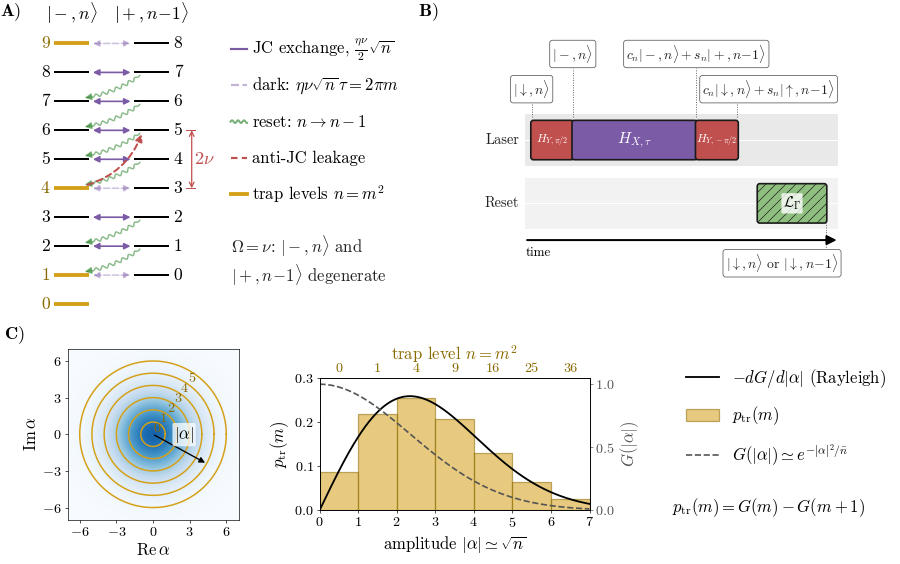

   saved -> figures\figure_1.png


In [15]:
# ==== FIGURES (supplementary_checks.ipynb loads the model from the cells above this marker)
# ==== FIGURES =================================================================

# Figure 1: pulse-sequence diagram
print("[fig 1] dressed-state ladder, pulse sequence, classical picture of the trapped distribution")


def wiggly_arrow(axh, p0, p1, rad=0.0, amp=5.0, wl=20.0, head=16.0, color="k", lw=2.0, alpha=1.0, z=1):
    """Wavy arrow (irreversible process) from p0 to p1 (data coords) along a quadratic Bezier
    with bend rad; amp, wl, head in pixels. Built in display coordinates so the wiggle is
    isotropic: call only once the axes position and limits are final."""
    T = axh.transData
    a, b = T.transform(p0), T.transform(p1)
    d = b - a; L = np.hypot(*d); nrm = np.array([-d[1], d[0]]) / L
    c = (a + b) / 2 + rad * L * nrm
    t = np.linspace(0, 1, 600)[:, None]
    cur = (1 - t) ** 2 * a + 2 * (1 - t) * t * c + t ** 2 * b
    sarc = np.r_[0, np.cumsum(np.hypot(*np.diff(cur, axis=0).T))]
    tan = np.gradient(cur, axis=0); tan /= np.hypot(*tan.T)[:, None]
    nor = np.c_[-tan[:, 1], tan[:, 0]]
    stop = sarc[-1] - head
    env = np.clip(sarc / wl, 0, 1) * np.clip((stop - sarc) / wl, 0, 1)
    pts = cur + (amp * np.sin(2 * np.pi * sarc / wl) * env)[:, None] * nor
    inv = T.inverted()
    xy = inv.transform(pts[sarc <= stop])
    axh.plot(xy[:, 0], xy[:, 1], color=color, lw=lw, alpha=alpha, zorder=z, solid_capstyle="round")
    i0 = np.searchsorted(sarc, stop)
    axh.add_patch(FancyArrowPatch(tuple(inv.transform(cur[i0])), tuple(inv.transform(b)), arrowstyle="-|>",
                                  mutation_scale=head, lw=lw, color=color, alpha=alpha, zorder=z,
                                  shrinkA=0, shrinkB=0))


def wiggly_line(axh, x0, x1, y, amp=4.0, wl=14.0, **kw):
    """Short wavy legend sample from (x0, y) to (x1, y), built in display coordinates."""
    T = axh.transData
    a, b = T.transform((x0, y)), T.transform((x1, y))
    xs = np.linspace(a[0], b[0], 200)
    xy = T.inverted().transform(np.c_[xs, a[1] + amp * np.sin(2 * np.pi * (xs - a[0]) / wl)])
    axh.plot(xy[:, 0], xy[:, 1], **kw)


red, purple, green_face, green = "#C0504D", "#7B5AA6", "#8FBF7F", "#3E8E3E"
gold, gold_dark, grey = "#D4A017", "#8a6a00", "#555555"
LW, ALW, FS = 2.4, 2.0, 17          # level lines, arrow lines, base font size
with plt.rc_context({"mathtext.fontset": "cm", "font.family": "serif",
                     "font.serif": ["cmr10", "Computer Modern Roman", "DejaVu Serif"],
                     "axes.formatter.use_mathtext": True,
                     "hatch.linewidth": 0.8, "savefig.bbox": "standard"}):
    fig = plt.figure(figsize=(15.0, 9.4), dpi=200)
    bx = fig.add_axes([0.0, 0.43, 0.46, 0.57])        # A) dressed-state ladder
    ax = fig.add_axes([0.5175, 0.487, 0.43, 0.456])   # B) pulse sequence, scaled to ~80% within its slot
    SB = 0.82                                         # font scale of panel B
    cx = fig.add_axes([0.075, 0.075, 0.19, 0.31])     # C) phase-space shells
    hx = fig.add_axes([0.355, 0.095, 0.30, 0.235])    # C) trapped distribution over the shells

    # ---------------- B) pulse sequence with the state of one Fock component ----------------
    row_h, row_gap = 0.80, 1.35                 # pulse-box height, spacing of row centres
    y_laser, y_meas = 3.0, 3.0 - row_gap
    lane_x0, lane_x1 = -0.15, 7.45
    lane_pad = row_h / 2 + 0.15
    for y, col in ((y_laser, "#e9e9e9"), (y_meas, "#f2f2f2")):
        ax.add_patch(mpatches.Rectangle((lane_x0, y - lane_pad), lane_x1 - lane_x0, 2 * lane_pad,
                                        facecolor=col, edgecolor="none", zorder=0))
        ax.plot([lane_x0, lane_x1], [y, y], color="white", lw=1.2, zorder=1)
    for name, y in (("Laser", y_laser), ("Reset", y_meas)):
        ax.text(lane_x0 - 0.15, y, name, ha="right", va="center", fontsize=SB * (FS + 4), color="#222222")
    narrow, wide, gap_after = 1.0, 3.0, 0.5
    x_diss = 2 * narrow + wide + gap_after
    # (x0, width, row, label, face, hatch, fontsize, font colour, white label backing)
    boxes = [
        (0.0, narrow, y_laser, r"$H_{Y,\pi/2}$", red, None, FS, "white", False),
        (narrow, wide, y_laser, r"$H_{X,\tau}$", purple, None, FS + 6, "white", False),
        (narrow + wide, narrow, y_laser, r"$H_{Y,-\pi/2}$", red, None, FS, "white", False),
        (x_diss, wide * 0.55, y_meas, r"$\mathcal{L}_{\Gamma}$", green_face, "//", FS + 4, "black", True),
    ]
    for x0, width, yc, label, face, hatch, fs, fc, backing in boxes:
        ax.add_patch(FancyBboxPatch((x0, yc - row_h / 2), width, row_h,
                                    boxstyle="round,pad=0.02,rounding_size=0.06", linewidth=2.0,
                                    edgecolor="#1a1a1a", facecolor=face, hatch=hatch, zorder=3))
        kw = dict(ha="center", va="center", fontsize=fs, color=fc, zorder=4)
        if backing:   # keeps the label legible over the hatch
            kw["bbox"] = dict(facecolor="white", alpha=0.8, edgecolor="none", boxstyle="round,pad=0.1")
        kw["fontsize"] = SB * fs
        ax.text(x0 + width / 2, yc, label, **kw)
    # state after each step, attached to the pulse boundaries: (x, tier height, label, ha, x offset)
    y_top = y_laser + lane_pad
    states = [
        (0.0, 0.30, r"$|{\downarrow},n\rangle$", "center", 0.0),
        (narrow, 1.05, r"$|-,n\rangle$", "center", 0.0),
        (narrow + wide, 1.05, r"$c_n|-,n\rangle+s_n|+,n\!-\!1\rangle$", "center", 0.0),
        (2 * narrow + wide, 0.30, r"$c_n|{\downarrow},n\rangle+s_n|{\uparrow},n\!-\!1\rangle$", "left", -0.85),
    ]
    for xb, dy, lab, ha, dx in states:
        ax.plot([xb, xb], [y_top - 0.05, y_top + dy - 0.06], color=grey, lw=1.1, ls=":", zorder=2)
        ax.text(xb + dx, y_top + dy, lab, ha=ha, va="bottom", fontsize=SB * (FS + 3), color="#222222",
                bbox=dict(facecolor="white", edgecolor=grey, lw=0.9, boxstyle="round,pad=0.2"))
    axis_y = y_meas - row_gap * 0.58
    ax.annotate("", xy=(lane_x1, axis_y), xytext=(lane_x0, axis_y),
                arrowprops=dict(arrowstyle="-|>", color="black", lw=2.4, mutation_scale=24))
    ax.text(lane_x0, axis_y - 0.14, "time", ha="left", va="top", fontsize=SB * (FS + 2))
    x_end = x_diss + wide * 0.55                 # post-reset state, below the time axis
    ax.plot([x_end, x_end], [y_meas - row_h / 2, axis_y - 0.22], color=grey, lw=1.1, ls=":", zorder=2)
    ax.text(lane_x1, axis_y - 0.26, r"$|{\downarrow},n\rangle$ or $|{\downarrow},n\!-\!1\rangle$",
            ha="right", va="top", fontsize=SB * (FS + 3), color="#222222",
            bbox=dict(facecolor="white", edgecolor=grey, lw=0.9, boxstyle="round,pad=0.2"))
    ax.set_xlim(lane_x0 - 1.45, lane_x1 + 0.35)
    ax.set_ylim(axis_y - 1.05, y_top + 1.75)
    ax.axis("off")
    fig.text(0.465, 0.9974, r"$\mathbf{B)}$", fontsize=FS + 5, va="top")   # level with A)

    # ---------------- A) dressed-state ladder at Omega = nu ----------------
    nmax = 9
    xl0, xl1 = 1.0, 2.5          # |-,n> column
    xr0, xr1 = 4.4, 5.9          # |+,n> column; |+,k> sits at the height of |-,k+1>
    traps_b = {n0 * m ** 2 for m in range(4)}
    for n in range(nmax + 1):
        t = n in traps_b
        bx.plot([xl0, xl1], [n, n], color=gold if t else "black", lw=LW + 2.2 if t else LW,
                solid_capstyle="butt", zorder=3)
        bx.text(xl0 - 0.18, n, f"{n}", ha="right", va="center", fontsize=FS + 4,
                color=gold_dark if t else "black")
    for k in range(nmax):
        bx.plot([xr0, xr1], [k + 1, k + 1], color="black", lw=LW, solid_capstyle="butt", zorder=3)
        bx.text(xr1 + 0.18, k + 1, f"{k}", ha="left", va="center", fontsize=FS + 4)
    bx.text((xl0 + xl1) / 2, nmax + 0.8, r"$|-,n\rangle$", ha="center", fontsize=FS + 4)
    bx.text((xr0 + xr1) / 2, nmax + 0.8, r"$|+,n\!-\!1\rangle$", ha="center", fontsize=FS + 4)
    for n in range(1, nmax + 1):     # resonant JC exchange |-,n> <-> |+,n-1>; dark on the trap levels
        t = n in traps_b
        bx.add_patch(FancyArrowPatch((xl1 + 0.08, n), (xr0 - 0.08, n), arrowstyle="<|-|>",
                                     mutation_scale=15, lw=ALW, color=purple,
                                     alpha=0.35 if t else 1.0, ls="--" if t else "-", zorder=2))
    # counter-rotating (anti-JC) leakage from a trap level, |-,4> -> |+,5>, detuned by 2 nu (coherent)
    bx.add_patch(FancyArrowPatch((xl1 - 0.15, 4 + 0.1), (xr0 + 0.35, 6 - 0.08),
                                 connectionstyle="arc3,rad=0.25", arrowstyle="-|>", mutation_scale=17,
                                 lw=ALW + 0.4, color=red, ls=(0, (3, 2)), zorder=5))
    xb2 = xr1 + 0.95
    bx.annotate("", xy=(xb2, 6), xytext=(xb2, 4),
                arrowprops=dict(arrowstyle="<->", color=red, lw=1.5, shrinkA=0, shrinkB=0, mutation_scale=14))
    for yy in (4, 6):
        bx.plot([xb2 - 0.25, xb2 + 0.12], [yy, yy], color=red, lw=1.2)
    bx.text(xb2 + 0.1, 5, r"$2\nu$", color=red, fontsize=FS + 5, va="center")
    lx, ly, dy = 8.5, 8.8, 1.25      # legend
    items = [
        (purple, "-", 1.0, r"JC exchange, $\frac{\eta\nu}{2}\sqrt{n}$"),
        (purple, "--", 0.45, r"dark: $\eta\nu\sqrt{n}\,\tau=2\pi m$"),
        (green, None, 0.7, r"reset: $n\to n-1$"),
        (red, (0, (3, 2)), 1.0, r"anti-JC leakage"),
    ]
    for i, (c, ls, al, lab) in enumerate(items):
        if ls is not None:
            bx.plot([lx, lx + 0.7], [ly - dy * i, ly - dy * i], color=c, lw=ALW + 0.6, ls=ls, alpha=al)
        bx.text(lx + 0.9, ly - dy * i, lab, va="center", fontsize=FS + 3)
    bx.plot([lx, lx + 0.7], [ly - dy * 4] * 2, color=gold, lw=LW + 2.2)
    bx.text(lx + 0.9, ly - dy * 4, r"trap levels $n=m^2$", va="center", fontsize=FS + 3)
    bx.text(lx, 1.5, r"$\Omega=\nu$: $|-,n\rangle$ and" "\n" r"$|+,n\!-\!1\rangle$ degenerate",
            fontsize=FS + 3, va="center", color="#222222")
    bx.set_xlim(-1.3, 16.3)
    bx.set_ylim(-0.6, nmax + 1.5)
    bx.axis("off")
    bx.text(-1.3, nmax + 1.45, r"$\mathbf{A)}$", fontsize=FS + 5, va="top")
    # irreversible reset |+,n-1> -> |-,n-1> (Y(-pi/2), decay, next Y(pi/2)): wavy, drawn once limits are final
    for n in range(2, nmax + 1):
        if n not in traps_b:
            wiggly_arrow(bx, (xr0 + 0.25, n - 0.1), (xl1 - 0.2, n - 1 + 0.12), rad=0.12,
                         amp=5.5, wl=24.0, head=16.0, color=green, lw=ALW - 0.2, alpha=0.6, z=1)
    wiggly_line(bx, lx, lx + 0.7, ly - dy * 2, amp=4.5, wl=20.0, color=green, lw=ALW + 0.4, alpha=0.7)

    # ---------------- C) classical picture: amplitude shells of the thermal phase-space Gaussian ----------------
    # G(r) = q^{r^2} = exp(-beta r^2), beta = nu/kT, is the probability of an amplitude above r; the trapped
    # weight of shell m is G(m) - G(m+1) = integral over the shell of the Rayleigh density -dG/dr (n0 = 1).
    beta = nu / KT
    m_show = 7
    rr = np.linspace(-m_show, m_show, 501)
    XX, YY = np.meshgrid(rr, rr)
    cx.imshow(np.exp(-beta * (XX ** 2 + YY ** 2)), extent=(-m_show, m_show, -m_show, m_show),
              origin="lower", cmap="Blues", vmin=0, vmax=1.25, interpolation="bilinear")
    th = np.linspace(0, 2 * np.pi, 400)
    for m in range(1, m_show):
        cx.plot(m * np.cos(th), m * np.sin(th), color=gold, lw=1.8)
    ang = np.deg2rad(55)
    for m in range(m_show - 1):
        cx.text((m + 0.5) * np.cos(ang), (m + 0.5) * np.sin(ang), f"{m}", ha="center", va="center",
                fontsize=FS, color=gold_dark, fontweight="bold")
    cx.annotate("", xy=(5.0 * np.cos(-0.5), 5.0 * np.sin(-0.5)), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.6, mutation_scale=14))
    cx.text(2.5 * np.cos(-0.5) + 0.35, 2.5 * np.sin(-0.5) + 0.35, r"$|\alpha|$", fontsize=FS + 3, ha="center",
            va="bottom", bbox=dict(facecolor="white", alpha=0.75, edgecolor="none", boxstyle="round,pad=0.1"))
    cx.set_xlim(-m_show, m_show); cx.set_ylim(-m_show, m_show); cx.set_aspect("equal")
    cx.set_xticks([-6, -3, 0, 3, 6]); cx.set_yticks([-6, -3, 0, 3, 6])
    cx.tick_params(labelsize=FS)
    cx.set_xlabel(r"${\rm Re}\,\alpha$", fontsize=FS + 3); cx.set_ylabel(r"${\rm Im}\,\alpha$", fontsize=FS + 3)
    fig.text(0.005, 0.425, r"$\mathbf{C)}$", fontsize=FS + 5, va="top")

    ms = np.arange(m_show)
    ptr = np.array([PID[n0 * m * m] if n0 * m * m < N else 0.0 for m in ms])
    hx.bar(ms, ptr, width=1.0, align="edge", color=gold, alpha=0.55, edgecolor=gold_dark, lw=1.5,
           label=r"$p_{\rm tr}(m)$")
    r = np.linspace(0, m_show, 400)
    hx.plot(r, 2 * beta * r * np.exp(-beta * r ** 2), color="black", lw=2.2,
            label=r"$-dG/d|\alpha|$ (Rayleigh)")
    gx = hx.twinx()
    gx.plot(r, np.exp(-beta * r ** 2), color=grey, ls="--", lw=2.0,
            label=r"$G(|\alpha|)\simeq e^{-|\alpha|^2/\bar n}$")
    hx.set_xlim(0, m_show); hx.set_ylim(0, 0.3); gx.set_ylim(0, 1.05)
    tx = hx.twiny()                              # top axis: trap level of each shell
    tx.set_xlim(0, m_show); tx.set_xticks(ms + 0.5)
    tx.set_xticklabels([f"{n0 * m * m}" for m in ms], fontsize=FS, color=gold_dark)
    tx.tick_params(length=0, pad=3)
    tx.set_xlabel(r"trap level $n=m^2$", fontsize=FS + 3, color=gold_dark)
    hx.set_xticks(range(m_show + 1))
    hx.tick_params(labelsize=FS); gx.tick_params(labelsize=FS, colors=grey)
    hx.set_xlabel(r"amplitude $|\alpha|\simeq\sqrt{n}$", fontsize=FS + 3)
    hx.set_ylabel(r"$p_{\rm tr}(m)$", fontsize=FS + 3)
    gx.set_ylabel(r"$G(|\alpha|)$", fontsize=FS + 3, color=grey)
    h1, l1 = hx.get_legend_handles_labels(); h2, l2 = gx.get_legend_handles_labels()
    fig.legend(h1 + h2, l1 + l2, loc="center left", bbox_to_anchor=(0.745, 0.26), frameon=False,
               fontsize=FS + 3, handlelength=2.0, labelspacing=0.9)
    fig.text(0.747, 0.10, r"$p_{\rm tr}(m)=G(m)-G(m+1)$", fontsize=FS + 3, va="center")
    print(f"   p_tr(m), m=0..{m_show - 1}: " + "  ".join(f"{p:.3f}" for p in ptr) +
          f";  Rayleigh peak at |alpha| = {np.sqrt(0.5 / beta):.2f}")

    fig.savefig(os.path.join(FIGDIR, "figure_1.png"), dpi=200, facecolor="white")
    show(fig, dpi=60)
    plt.close(fig)
    print(f"   saved -> {os.path.relpath(os.path.join(FIGDIR, 'figure_1.png'), HERE)}")

## Figure 2: final populations

The nominal resonant sequence ($f=1$, no delay) is run for $R=80$ cycles at $\eta=0.01,0.05,0.1,0.2$. The plot shows the initial thermal populations (red), the final populations (blue bars) and the ideal trap (crosses). The horizontal axis is $\sqrt n$, so the trap levels $n=m^2$ are equally spaced.

The printed lines give the trace distance, the weight left off the trap levels, and the trap-level populations against their targets.

[fig 2] final populations vs eta


   eta=0.01  TD=0.0037; weight off the trap levels 0.003 (largest: n=37:0.001, n=26:0.001, n=50:0.000); trap levels final/ideal: 0:0.087/0.087  1:0.218/0.218  4:0.254/0.254  9:0.207/0.208  16:0.130/0.130  25:0.064/0.065  36:0.025/0.026


   eta=0.05  TD=0.0789; weight off the trap levels 0.068 (largest: n=17:0.011, n=26:0.010, n=10:0.007); trap levels final/ideal: 0:0.083/0.087  1:0.225/0.218  4:0.258/0.254  9:0.202/0.208  16:0.110/0.130  25:0.041/0.065  36:0.011/0.026


   eta=0.1   TD=0.2599; weight off the trap levels 0.190 (largest: n=10:0.027, n=17:0.025, n=5:0.014); trap levels final/ideal: 0:0.075/0.087  1:0.260/0.218  4:0.282/0.254  9:0.150/0.208  16:0.036/0.130  25:0.006/0.065  36:0.001/0.026


   eta=0.2   TD=0.5131; weight off the trap levels 0.332 (largest: n=5:0.033, n=2:0.020, n=10:0.017); trap levels final/ideal: 0:0.075/0.087  1:0.399/0.218  4:0.150/0.254  9:0.019/0.208  16:0.007/0.130  25:0.007/0.065  36:0.008/0.026


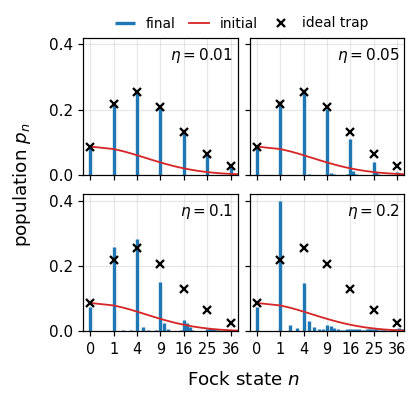

   saved -> figures\figure_2.pdf


In [16]:
# Figure 2: initial vs final populations for several eta
print("[fig 2] final populations vs eta")
# x axis in sqrt(n), so the trap levels n = m^2 are equally spaced
fig, axes = plt.subplots(2, 2, figsize=(3.6, 3.4), sharex=True, sharey=True)
sq_n = np.sqrt(np.arange(N))
traps = np.nonzero(PID)[0]
m_max = 6
for ax, eta in zip(axes.flat, FIG2_ETAS):
    p_fin = cached(("fig2", eta), lambda: iterate(U_new(eta), eta, P0))
    ax.vlines(sq_n, 0, p_fin, color="tab:blue", lw=2.2, label="final")
    ax.plot(sq_n, P0, "-", color="tab:red", lw=1.2, label="initial")
    ax.plot(np.sqrt(traps), PID[traps], "x", color="k", ms=5, mew=1.5, label="ideal trap")
    ax.text(0.97, 0.94, rf"$\eta={eta:g}$", transform=ax.transAxes, ha="right", va="top", fontsize=10)
    ax.set_xlim(-0.3, m_max + 0.3); ax.set_ylim(0, 0.42)
    ax.set_xticks(range(m_max + 1)); ax.set_xticklabels([str(m * m) for m in range(m_max + 1)], fontsize=9.5)
    ax.tick_params(axis="y", labelsize=10)
    ax.grid(True, alpha=0.3)
    off = np.setdiff1d(np.arange(N), traps)
    k_off = off[np.argsort(p_fin[off])[::-1][:3]]
    print(f"   eta={eta:<5g} TD={tdist(p_fin, PID):.4f}; weight off the trap levels {p_fin[off].sum():.3f} "
          f"(largest: " + ", ".join(f"n={k}:{p_fin[k]:.3f}" for k in k_off) + "); trap levels final/ideal: " +
          "  ".join(f"{k}:{p_fin[k]:.3f}/{PID[k]:.3f}" for k in traps[:7]))
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", bbox_to_anchor=(0.57, 0.935), ncol=3, frameon=False,
           fontsize=9, handlelength=1.4, columnspacing=1.0, borderaxespad=0.0)
left, right, bottom, top = 0.17, 0.98, 0.145, 0.93
fig.subplots_adjust(left=left, right=right, bottom=bottom, top=top, wspace=0.08, hspace=0.14)
fig.text((left + right) / 2, 0.015, r"Fock state $n$", ha="center", va="center", fontsize=12)
fig.text(0.015, (bottom + top) / 2, r"population $p_n$", ha="center", va="center", rotation=90, fontsize=12)
save(fig, "figure_2.pdf")

## Figure 3: weak-driving SPT vs the resonant sequence

The two protocols are compared over the same number of cycles.
- **(A)** Trace distance against the Rabi frequency $\Omega$ for the weak-driving SPT protocol, the red-sideband pulse of length $2\pi/(\eta\Omega)$ (circles). The resonant sequence at $\Omega=\nu$ is marked with crosses. The cell also gives the weak-driving protocol the same freedom to recalibrate its pulse length (referee comment M2(c)); the result is printed and quoted in Sec. III A, not plotted.
- **(B)** Trace distance against $\eta$, for the weak-driving protocol at $\Omega=10^{-3}\nu$ and the nominal resonant sequence.

In [17]:
# Figure 3: weak-driving SPT protocol vs resonant sequence
print("[fig 3] weak-driving vs resonant: Omega scan and eta scan")
_old_specs = [dict(eta=eta, Om=float(Om)) for eta in FIG3_ETAS for Om in FIG3_OMEGAS]
_v = cached_map([("fig3_old", s["eta"], s["Om"]) for s in _old_specs], sim_old, _old_specs, "fig3 Omega scan")
td_old_om = {eta: np.array(_v[k * len(FIG3_OMEGAS):(k + 1) * len(FIG3_OMEGAS)]) for k, eta in enumerate(FIG3_ETAS)}
td_new_nu = {eta: cached(("fig3_new", eta), lambda: td_new(eta)) for eta in FIG3_ETAS}
_sw = [float(e) for e in FIG3_ETA_SWEEP]
td_old_eta = np.array(cached_map([("fig3_old", e, FIG3_OMEGA_OLD) for e in _sw], sim_old,
                                 [dict(eta=e, Om=FIG3_OMEGA_OLD) for e in _sw], "fig3 eta sweep, weak"))
td_new_eta = np.array(cached_map([("fig3_new", e) for e in _sw], sim, [dict(eta=e) for e in _sw],
                                 "fig3 eta sweep, resonant"))
# referee M2(c): the weak-driving protocol with the same freedom to recalibrate its pulse length
# (printed and quoted in the text; not plotted since 2026-11-16)
_rc_specs = [dict(eta=e, Om=Om, f=_r(f)) for e in FIG3_RECAL_ETAS for Om in FIG3_RECAL_OMEGAS for f in FIG3_RECAL_F]
_v = np.array(cached_map([("fig3_old_f", s["eta"], s["Om"], s["f"]) for s in _rc_specs], sim_old, _rc_specs,
                         "fig3 weak recalibration")).reshape(len(FIG3_RECAL_ETAS), len(FIG3_RECAL_OMEGAS), -1)
recal_old = {}
for a, e in enumerate(FIG3_RECAL_ETAS):
    for b, Om in enumerate(FIG3_RECAL_OMEGAS):
        k = int(np.argmin(_v[a, b])); recal_old[(e, Om)] = (_v[a, b, k], FIG3_RECAL_F[k])
        print(f"   weak-driving, eta={e:g}, Omega={Om:g}: f=1 {_v[a, b, int(np.argmin(np.abs(FIG3_RECAL_F - 1)))]:.4f}; "
              f"best pulse length f={FIG3_RECAL_F[k]:.3f}: {_v[a, b, k]:.4f}")
for eta in FIG3_ETAS:
    print(f"   eta={eta:<5g} new(Omega=nu)={td_new_nu[eta]:.4f}  old: " +
          "  ".join(f"{Om:g}:{v:.3f}" for Om, v in zip(FIG3_OMEGAS, td_old_om[eta])))
print("   eta sweep (old/new): " + "  ".join(f"{e:.3f}:{o:.3f}/{n:.3f}"
                                            for e, o, n in zip(FIG3_ETA_SWEEP, td_old_eta, td_new_eta)))
_ratio = td_old_eta / td_new_eta
_m = FIG3_ETA_SWEEP <= 0.1 + 1e-9
print(f"   ratio weak/resonant for eta <= 0.1: min {_ratio[_m].min():.2f}, median {np.median(_ratio[_m]):.2f}, "
      f"max {_ratio[_m].max():.2f}")

[fig 3] weak-driving vs resonant: Omega scan and eta scan


   weak-driving, eta=0.02, Omega=0.01: f=1 0.1529; best pulse length f=1.000: 0.1529


   weak-driving, eta=0.02, Omega=0.001: f=1 0.0486; best pulse length f=1.005: 0.0277


   weak-driving, eta=0.05, Omega=0.01: f=1 0.2730; best pulse length f=1.015: 0.1833


   weak-driving, eta=0.05, Omega=0.001: f=1 0.2834; best pulse length f=1.015: 0.1760


   weak-driving, eta=0.1, Omega=0.01: f=1 0.5806; best pulse length f=1.035: 0.3584


... (3 outputs left out)

   eta=0.1   new(Omega=nu)=0.2599  old: 0.001:0.584  0.002:0.584  0.005:0.583  0.01:0.581  0.02:0.569  0.05:0.475  0.1:0.619  0.2:0.677  0.5:0.625  1:0.685  2:0.859  4:0.703  8:0.706


   eta=0.2   new(Omega=nu)=0.5131  old: 0.001:0.678  0.002:0.678  0.005:0.678  0.01:0.678  0.02:0.678  0.05:0.677  0.1:0.673  0.2:0.797  0.5:0.811  1:0.783  2:0.634  4:0.749  8:0.682


   eta sweep (old/new): 0.020:0.049/0.012  0.025:0.084/0.019  0.030:0.124/0.019  0.035:0.169/0.015  0.040:0.197/0.050  0.045:0.221/0.054  0.050:0.283/0.079  0.055:0.350/0.068  0.060:0.390/0.075  0.065:0.394/0.065  0.070:0.395/0.115  0.075:0.411/0.108  0.080:0.426/0.177  0.085:0.422/0.165  0.090:0.460/0.113  0.095:0.536/0.158  0.100:0.584/0.260  0.105:0.613/0.197  0.110:0.596/0.144  0.115:0.580/0.233  0.120:0.588/0.222  0.125:0.616/0.336  0.130:0.600/0.267  0.135:0.679/0.200  0.140:0.661/0.249  0.145:0.650/0.235  0.150:0.676/0.288  0.155:0.685/0.244  0.160:0.675/0.354  0.165:0.686/0.273  0.170:0.684/0.304  0.175:0.680/0.383  0.180:0.619/0.330  0.185:0.607/0.311  0.190:0.672/0.418  0.195:0.661/0.338  0.200:0.678/0.513  0.210:0.694/0.473  0.220:0.687/0.464  0.230:0.684/0.392  0.240:0.683/0.459  0.250:0.643/0.581  0.260:0.716/0.456  0.270:0.715/0.548  0.280:0.667/0.477  0.290:0.737/0.464  0.300:0.651/0.541  0.310:0.652/0.577  0.320:0.711/0.492  0.330:0.778/0.604  0.340:0.804/0.487  0.350:0

   ratio weak/resonant for eta <= 0.1: min 2.25, median 4.02, max 11.12


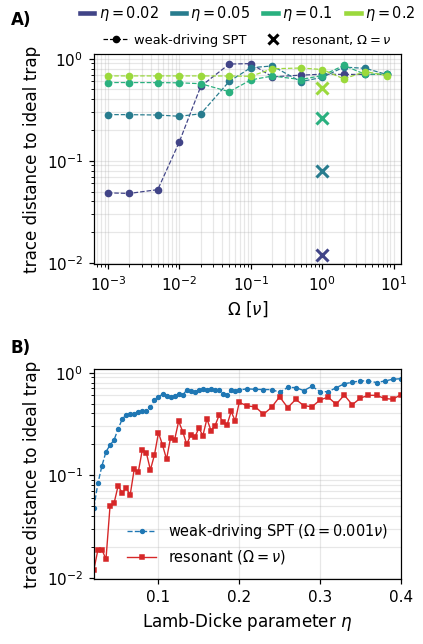

   saved -> figures\figure_3_plus_trace.pdf


In [18]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(3.6, 6.2), gridspec_kw={"hspace": 0.5})
cols = plt.cm.viridis(np.linspace(0.2, 0.85, len(FIG3_ETAS)))
idx_nu = int(np.argmin(np.abs(FIG3_OMEGAS - OMEGA)))
for c, eta in zip(cols, FIG3_ETAS):
    a1.plot(FIG3_OMEGAS, td_old_om[eta], marker="o", linestyle="--", lw=0.8, color=c, ms=4)
    a1.plot([FIG3_OMEGAS[idx_nu]], [td_new_nu[eta]], marker="x", linestyle="None",
            color=c, ms=8, mew=2.0)
a1.set_xscale("log"); a1.set_yscale("log")
a1.set_xlabel(r"$\Omega$ $[\nu]$")
a1.set_ylabel("trace distance to ideal trap")
a1.grid(True, which="both", alpha=0.3)
leg_eta = a1.legend(handles=[Line2D([0], [0], color=c, lw=3, label=rf"$\eta={v:g}$")
                             for c, v in zip(cols, FIG3_ETAS)],
                    loc="lower center", bbox_to_anchor=(0.5, 1.12), ncol=len(FIG3_ETAS),
                    frameon=False, borderaxespad=0.0, handlelength=1.0,
                    handletextpad=0.3, columnspacing=0.9)
a1.add_artist(leg_eta)
a1.legend(handles=[Line2D([0], [0], color="k", lw=0.8, linestyle="--", marker="o", ms=4,
                          label="weak-driving SPT"),
                   Line2D([0], [0], color="k", lw=0, marker="x", ms=7, mew=2.0,
                          label=r"resonant, $\Omega=\nu$")],
          loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False,
          borderaxespad=0.0, handlelength=2.0, handletextpad=0.4, columnspacing=1.0, fontsize=8.5)
a1.text(-0.27, 1.12, "A)", transform=a1.transAxes, va="bottom", fontweight="bold")
a2.plot(FIG3_ETA_SWEEP, td_old_eta, marker="o", linestyle="--", color="tab:blue", ms=2.5, lw=0.9,
        label=rf"weak-driving SPT ($\Omega={FIG3_OMEGA_OLD:g}\nu$)")
a2.plot(FIG3_ETA_SWEEP, td_new_eta, marker="s", linestyle="-", color="tab:red", ms=2.5, lw=0.9,
        label=r"resonant ($\Omega=\nu$)")
a2.set_xlabel(r"Lamb-Dicke parameter $\eta$")
a2.set_ylabel("trace distance to ideal trap")
a2.set_yscale("log"); a2.grid(True, which="both", alpha=0.3)
a2.set_xlim(FIG3_ETA_SWEEP.min(), FIG3_ETA_SWEEP.max())
a2.legend(loc="lower right", frameon=False)
a2.text(-0.27, 1.06, "B)", transform=a2.transAxes, va="bottom", fontweight="bold")
save(fig, "figure_3_plus_trace.pdf")

## Figure 4: preparation from a Doppler-cooled ion

- **(A)** The trace distance after each cycle at $\eta=0.05$, against the preparation time. The resonant sequence is compared with the weak-driving protocol at $\Omega=\nu/100$ and $\nu/1000$. The top axis converts to ms for $\nu=2\pi\times1$ MHz, and the dotted line marks $R=80$ cycles.
- **(B)** The trace distance after $R$ cycles against the initial $\bar n$ of a thermal state, for $\eta=0.02,0.05,0.1$, with no ground-state cooling. The shaded band is the typical range of Doppler limits, and the dashed line is $\bar n=10.5$.

[fig 4] preparation from a Doppler-cooled ion, eta = 0.05


   resonant, $\Omega=\nu$               TD after R=80: 0.0789; min 0.0788 at cycle 77; within 10% of min after 39 cycles (t nu = 4.9e+03, 0.78 ms); R cycles = 1.6 ms


   weak-driving SPT, $\Omega=\nu/100$   TD after R=80: 0.2730; min 0.2422 at cycle 27; within 10% of min after 14 cycles (t nu = 1.76e+05, 28 ms); R cycles = 160 ms

   weak-driving SPT, $\Omega=\nu/1000$  TD after R=80: 0.2834; min 0.2466 at cycle 26; within 10% of min after 14 cycles (t nu = 1.76e+06, 280 ms); R cycles = 1.6e+03 ms


   eta=0.02  TD after R: 0.1:0.007  0.3:0.006  0.5:0.005  1:0.004  2:0.003  3:0.003  5:0.005  7:0.006  10:0.011  12.5:0.016  15:0.022


              cycles to floor: 0.1:4  0.3:6  0.5:8  1:12  2:20  3:28  5:43  7:57  10:74  12.5:87  15:99


   eta=0.05  TD after R: 0.1:0.045  0.3:0.038  0.5:0.033  1:0.025  2:0.021  3:0.022  5:0.030  7:0.044  10:0.074  12.5:0.101  15:0.129


              cycles to floor: 0.1:2  0.3:4  0.5:6  1:8  2:14  3:18  5:27  7:34  10:38  12.5:42  15:46


   eta=0.1   TD after R: 0.1:0.165  0.3:0.138  0.5:0.119  1:0.093  2:0.083  3:0.091  5:0.121  7:0.173  10:0.248  12.5:0.303  15:0.351


              cycles to floor: 0.1:2  0.3:4  0.5:4  1:8  2:10  3:12  5:14  7:16  10:16  12.5:15  15:14


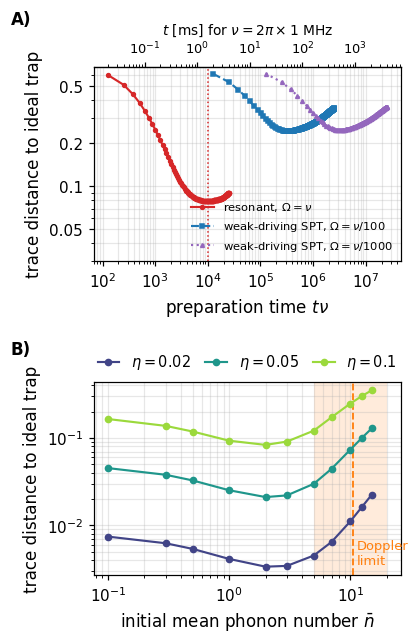

   saved -> figures\figure_preparation.pdf


In [19]:
# Figure 4 (preparation): (A) trace distance vs preparation time at eta_ref,
# (B) final trace distance vs initial temperature (no ground-state cooling)
print(f"[fig 4] preparation from a Doppler-cooled ion, eta = {ETA_REF}")
runs = [(r"resonant, $\Omega=\nu$", "new", t_cycle_new(ETA_REF), "o-", "tab:red")]
for Om, mk, col in zip(CONV_OMEGAS_OLD, ("s--", "^:"), ("tab:blue", "tab:purple")):
    runs.append((rf"weak-driving SPT, $\Omega=\nu/{int(round(1 / Om))}$", Om, t_cycle_old(ETA_REF, Om), mk, col))
fig, (a1, a2) = plt.subplots(2, 1, figsize=(3.6, 6.0), gridspec_kw={"hspace": 0.62})
to_ms = lambda x: x / (2 * np.pi * NU_HZ) * 1e3
for lab, which, tc, mk, col in runs:
    U = U_new(ETA_REF) if which == "new" else U_old(ETA_REF, which)
    hist = cached(("conv", str(which), ETA_REF, CONV_CYCLES),
                  lambda: iterate(U, ETA_REF, P0, CONV_CYCLES, record=True)[1])
    td = np.array([tdist(h, PID) for h in hist])
    t = np.arange(len(td)) * tc
    a1.plot(t[1:] * nu, td[1:], mk, color=col, ms=2.5, label=lab)
    k = cycles_to_floor(td)
    print(f"   {lab:36s} TD after R={R}: {td[min(R, len(td) - 1)]:.4f}; min {td.min():.4f} at cycle {td.argmin()}; "
          f"within 10% of min after {k} cycles (t nu = {t[k]:.3g}, {to_ms(t[k]):.3g} ms); "
          f"R cycles = {to_ms(R * tc):.3g} ms")
a1.axvline(R * t_cycle_new(ETA_REF), color="tab:red", ls=":", lw=1)
a1.set_xscale("log"); a1.set_yscale("log")
a1.set_xlabel(r"preparation time $t\nu$")
a1.set_ylabel("trace distance to ideal trap")
a1.grid(True, which="both", alpha=0.3)
a1.set_ylim(bottom=0.03)                                  # room below the curves for the legend
a1.set_yticks([0.05, 0.1, 0.2, 0.5]); a1.set_yticklabels(["0.05", "0.1", "0.2", "0.5"])
a1.yaxis.set_minor_formatter(plt.NullFormatter())
a1.legend(frameon=False, loc="lower right", fontsize=7.5, borderaxespad=0.3, handlelength=2.0)
sx = a1.secondary_xaxis("top", functions=(to_ms, lambda y: y * (2 * np.pi * NU_HZ) / 1e3))
sx.set_xlabel(r"$t$ [ms] for $\nu=2\pi\times1$ MHz", fontsize=9)
sx.tick_params(labelsize=8.5)
a1.text(-0.27, 1.2, "A)", transform=a1.transAxes, va="bottom", fontweight="bold")

dop_td, dop_k = {}, {}
for eta in DOPPLER_ETAS:
    dop_td[eta], dop_k[eta] = [], []
    for nb in DOPPLER_NBARS:
        def _run():
            p = thermal_p(kT_of_nbar(nb)); pid = ideal_trapped(p)
            _, hist = iterate(U_new(eta), eta, p, DOPPLER_CYCLES, record=True)
            return np.array([tdist(h, pid) for h in hist])
        td = cached(("doppler", eta, float(nb), DOPPLER_CYCLES), _run)
        dop_td[eta].append(td[min(R, len(td) - 1)]); dop_k[eta].append(cycles_to_floor(td))
    print(f"   eta={eta:<5g} TD after R: " + "  ".join(f"{nb:g}:{v:.3f}" for nb, v in zip(DOPPLER_NBARS, dop_td[eta])))
    print(f"   {'':10s} cycles to floor: " + "  ".join(f"{nb:g}:{k}" for nb, k in zip(DOPPLER_NBARS, dop_k[eta])))
cols = plt.cm.viridis(np.linspace(0.2, 0.85, len(DOPPLER_ETAS)))
a2.axvspan(*DOPPLER_BAND, color="tab:orange", alpha=0.15, lw=0)
a2.axvline(NBAR, color="tab:orange", ls="--", lw=1.2)
for c, eta in zip(cols, DOPPLER_ETAS):
    a2.plot(DOPPLER_NBARS, dop_td[eta], "o-", color=c, label=rf"$\eta={eta:g}$")
a2.set_xscale("log"); a2.set_yscale("log")
a2.set_xlabel(r"initial mean phonon number $\bar n$")
a2.set_ylabel("trace distance to ideal trap")
a2.grid(True, which="both", alpha=0.3)
a2.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3,
          borderaxespad=0.0, handlelength=1.5, columnspacing=1.0)
a2.text(NBAR * 1.07, 0.04, "Doppler\nlimit", transform=a2.get_xaxis_transform(),
        color="tab:orange", fontsize=8.5, va="bottom")
a2.text(-0.27, 1.12, "B)", transform=a2.transAxes, va="bottom", fontweight="bold")
save(fig, "figure_preparation.pdf")

## Figure 5: counter-rotating leakage and timing calibration

**The mechanism.** The leakage comes from the counter-rotating (anti-Jaynes–Cummings) term of the $X$ pulse, which is off-resonant by $2\nu$. The one-cycle map is stroboscopic: the motional coherences left by one cycle enter the next. The error therefore depends on two times, the pulse length $f\tau$ and the free evolution $t_d$ after each reset.

**(B) The calibration versus $\eta$.** The cell below calibrates both on the fine $\eta$ grid. It then adds a Rabi-frequency offset $\delta\Omega$ on top of the calibrated timing for $\eta\ge0.05$, which is a secondary knob. The printed table gives, for each $\eta$:
- the nominal error;
- the error after calibrating the pulse length only;
- the error after calibrating the pulse length and the delay;
- the error with $\delta\Omega$ added.

Large gains from the pulse length alone occur only where $2/\eta$ is an integer (marked `*`).

In [20]:
# Figure 5: timing calibration (referee M3). The one-cycle map is stroboscopic: motional coherences left
# by one cycle enter the next, so the error depends on the pulse length f tau and on the free evolution
# ("delay") between cycles. Large errors occur when the X pulse spans a whole number of half trap periods
# (2/eta integer) and the cycles follow each other without delay.
print(f"[fig 5] timing calibration on the fine eta grid ({len(ETA_FINE)} values)")
CAL = calibrate_many(ETA_FINE, "ref", "fig5 timing")
_dom_specs = []
for e in FIG5_DOM_ETAS:
    _, fj, dj = CAL[_r(e)]["joint"]
    _dom_specs += [dict(eta=_r(e), f=_r(fj + e * fr), delay=_r(dj), dOm=_r(de), model="ref")
                   for de in FIG5_DOM_SCAN for fr in FIG5_DOM_F_REL]
_v = run_sims("cal", _dom_specs, "fig5 Rabi offset")
for e in FIG5_DOM_ETAS:
    c = [(v, s["f"], s["delay"], s["dOm"]) for s, v in zip(_dom_specs, _v) if s["eta"] == _r(e)]
    CAL[_r(e)]["dom"] = min(c, key=lambda t: t[0])
calib = {}                        # final calibration of the reference model, used by Figs. 6, 7 and robustness
print("   eta    2/eta   nominal  | f only: TD   (f-1) tau nu | f+delay: TD  (f-1) tau nu  delay nu | "
      "+dOm: TD  dOm   | gain f-only / f+delay / all")
for e in ETA_FINE:
    c = CAL[_r(e)]
    tdj, fj, dj = c["joint"]
    best = (tdj, fj, dj, 0.0)
    if "dom" in c and c["dom"][0] < tdj:
        best = c["dom"]
    calib[_r(e)] = dict(td=best[0], f=best[1], delay=best[2], dOm=best[3])
    dom_s = f"{c['dom'][0]:.4f} {c['dom'][3]:+.3f}" if "dom" in c else " " * 13
    print(f"   {e:.3f}  {2 / e:6.2f}{'*' if abs(2 / e - round(2 / e)) < 1e-6 else ' '}  {c['nom']:.4f}  | "
          f"{c['f_only'][0]:.4f}  {(c['f_only'][1] - 1) * tau_of(e):+.3f}       | {tdj:.4f}  {(fj - 1) * tau_of(e):+.3f}"
          f"        {dj:.3f}   | {dom_s} | x{c['nom'] / c['f_only'][0]:.2f} / x{c['nom'] / tdj:.2f} / "
          f"x{c['nom'] / best[0]:.2f}")
_comm = np.array([abs(2 / e - round(2 / e)) < 1e-6 for e in ETA_FINE])
for nm, msk in (("2/eta integer", _comm), ("2/eta non-integer", ~_comm)):
    if msk.any():
        g1 = np.array([CAL[_r(e)]["nom"] / CAL[_r(e)]["f_only"][0] for e in ETA_FINE[msk]])
        g2 = np.array([CAL[_r(e)]["nom"] / CAL[_r(e)]["joint"][0] for e in ETA_FINE[msk]])
        print(f"   {nm:18s}: gain f only {g1.min():.2f}-{g1.max():.2f} (median {np.median(g1):.2f}); "
              f"f+delay {g2.min():.2f}-{g2.max():.2f} (median {np.median(g2):.2f})")
_mean_nom = {e: CAL[_r(e)]["grid"][int(np.argmin(np.abs(CAL_F_REL))), :].mean() for e in ETA_FINE}
print("   nominal pulse, error averaged over the delay: " +
      "  ".join(f"{e:g}:{_mean_nom[e]:.3f}" for e in ETA_FINE[::2]))

[fig 5] timing calibration on the fine eta grid (37 values)


   eta    2/eta   nominal  | f only: TD   (f-1) tau nu | f+delay: TD  (f-1) tau nu  delay nu | +dOm: TD  dOm   | gain f-only / f+delay / all


   0.020  100.00*  0.0121  | 0.0055  +0.251       | 0.0049  +0.188        0.150   |               | x2.18 / x2.46 / x2.46


   0.025   80.00*  0.0188  | 0.0079  +0.251       | 0.0070  +0.188        0.150   |               | x2.39 / x2.69 / x2.69


   0.030   66.67   0.0189  | 0.0141  +0.251       | 0.0118  +0.251        0.543   |               | x1.34 / x1.60 / x1.60


   0.035   57.14   0.0152  | 0.0149  +0.063       | 0.0141  +0.063        6.083   |               | x1.02 / x1.08 / x1.08


... (32 outputs left out)

   0.200   10.00*  0.5131  | 0.3040  +0.440       | 0.2835  +0.440        0.193   | 0.2741 -0.020 | x1.69 / x1.81 / x1.87


   2/eta integer     : gain f only 1.69-2.88 (median 2.45); f+delay 1.81-3.23 (median 2.62)


   2/eta non-integer : gain f only 1.00-1.79 (median 1.20); f+delay 1.00-1.80 (median 1.26)


   nominal pulse, error averaged over the delay: 0.02:0.011  0.03:0.085  0.04:0.041  0.05:0.068  0.06:0.217  0.07:0.248  0.08:0.286  0.09:0.247  0.1:0.235  0.11:0.305  0.12:0.421  0.13:0.446  0.14:0.426  0.15:0.488  0.16:0.500  0.17:0.509  0.18:0.526  0.19:0.545  0.2:0.550


A diagnostic that is only printed: at non-commensurate $\eta$, make the $X$ pulse span a whole number of half trap periods, $f=k\eta/2$. The trapping condition is restored by retuning $\Omega=\nu/f$, and the delay is scanned. This retuning is worse than the joint calibration of $(f,t_d)$.

In [21]:
# Diagnostic (log only): at non-commensurate eta, make the X pulse span k half trap periods, f = k eta/2,
# and restore the trap condition eta Omega f tau = 2 pi with Omega = nu/f (|dOm| <~ eta/4), scanning the delay.
_rc_specs = []
for e in ETA_FINE[~_comm]:
    for k in (int(np.floor(2 / e)), int(np.ceil(2 / e))):
        f_k = k * e / 2
        _rc_specs += [dict(eta=_r(e), f=_r(f_k), dOm=_r(1 / f_k - 1), delay=_r(d), model="ref") for d in CAL_DELAYS]
_v = run_sims("cal", _rc_specs, "fig5 recommensuration")
print("   recommensurated pulse (f = k eta/2, Omega = nu/f, best delay) vs joint (f, delay) calibration:")
for e in ETA_FINE[~_comm]:
    c = [(v, s["f"], s["dOm"], s["delay"]) for s, v in zip(_rc_specs, _v) if s["eta"] == _r(e)]
    b = min(c, key=lambda t: t[0])
    print(f"      eta={e:.3f}: recommensurated {b[0]:.4f} (f={b[1]:.4f}, dOm={b[2]:+.4f}, delay {b[3]:.2f}/nu)  "
          f"joint {CAL[_r(e)]['joint'][0]:.4f}  nominal {CAL[_r(e)]['nom']:.4f}")

   recommensurated pulse (f = k eta/2, Omega = nu/f, best delay) vs joint (f, delay) calibration:


      eta=0.030: recommensurated 0.0760 (f=1.0050, dOm=-0.0050, delay 0.79/nu)  joint 0.0118  nominal 0.0189


      eta=0.035: recommensurated 0.0301 (f=0.9975, dOm=+0.0025, delay 5.89/nu)  joint 0.0141  nominal 0.0152


      eta=0.045: recommensurated 0.1272 (f=0.9900, dOm=+0.0101, delay 1.96/nu)  joint 0.0369  nominal 0.0535


      eta=0.055: recommensurated 0.1554 (f=0.9900, dOm=+0.0101, delay 5.89/nu)  joint 0.0677  nominal 0.0677


      eta=0.060: recommensurated 0.1434 (f=0.9900, dOm=+0.0101, delay 5.89/nu)  joint 0.0670  nominal 0.0746


... (20 outputs left out)

      eta=0.180: recommensurated 0.3969 (f=0.9900, dOm=+0.0101, delay 5.89/nu)  joint 0.2385  nominal 0.3303


      eta=0.185: recommensurated 0.3818 (f=1.0175, dOm=-0.0172, delay 0.39/nu)  joint 0.2578  nominal 0.3114


      eta=0.190: recommensurated 0.5750 (f=1.0450, dOm=-0.0431, delay 0.79/nu)  joint 0.2931  nominal 0.4184


      eta=0.195: recommensurated 0.5571 (f=0.9750, dOm=+0.0256, delay 5.89/nu)  joint 0.3355  nominal 0.3380


**(A) The $(f,t_d)$ map at $\eta=0.05$.** The cell below draws both panels: the map on top and the $\eta$ scan computed above underneath. In the map, the trace distance is shown against the pulse lengthening $(f-1)\tau$ and the delay.
- **Circle.** The nominal sequence.
- **Star.** The calibrated optimum quoted in the text, `CAL[eta]["joint"]`, which comes from the local refinement between the grid points.
- **Bright bands** at the lower left and upper right. They follow full cycle periods $f\tau+\pi/\Omega_Y+T_{\rm reset}+t_d$ equal to a whole number of trap periods: a stroboscopic resonance. It is analysed in `supplementary_checks.ipynb`.

   map at eta=0.05: optimum lengthening +0.251/nu (f=1.00200), delay 0.175/nu, TD=0.0248; nominal 0.0789; best f for the delay-averaged error: lengthening +0.126/nu -> 0.0609 (f=1: 0.0640)


   fig 5(A) star: calibrated optimum lengthening +0.251/nu, delay 0.100/nu, TD=0.0245 (map-grid minimum 0.0248)


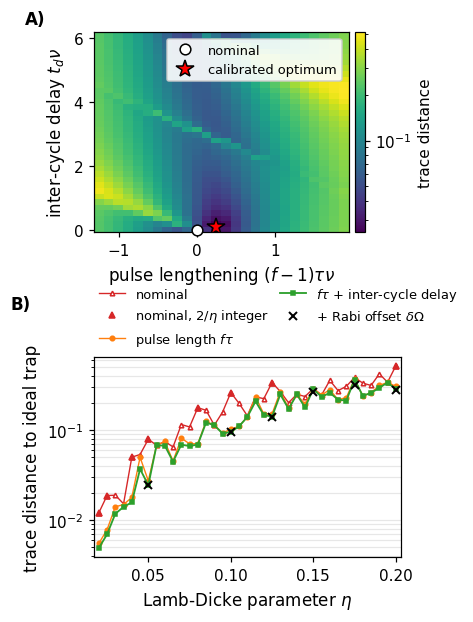

   saved -> figures\figure_5.pdf


In [22]:
# map at eta_ref
_e = _r(FIG5_MAP_ETA)
_map_specs = [dict(eta=_e, f=_r(1 + _e * fr), delay=_r(d), model="ref") for fr in FIG5_MAP_F_REL for d in FIG5_MAP_DELAYS]
TD = np.array(run_sims("cal", _map_specs, "fig5 map")).reshape(len(FIG5_MAP_F_REL), len(FIG5_MAP_DELAYS)).T
i_b, j_b = np.unravel_index(np.argmin(TD), TD.shape)
X_SHIFT = FIG5_MAP_F_REL * _e * tau_of(_e)          # pulse lengthening (f-1) tau, in units of 1/nu
print(f"   map at eta={_e}: optimum lengthening {X_SHIFT[j_b]:+.3f}/nu (f={1 + _e * FIG5_MAP_F_REL[j_b]:.5f}), "
      f"delay {FIG5_MAP_DELAYS[i_b]:.3f}/nu, TD={TD[i_b, j_b]:.4f}; nominal {CAL[_e]['nom']:.4f}; "
      f"best f for the delay-averaged error: lengthening {X_SHIFT[int(np.argmin(TD.mean(0)))]:+.3f}/nu -> "
      f"{TD.mean(0).min():.4f} (f=1: {TD.mean(0)[int(np.argmin(np.abs(FIG5_MAP_F_REL)))]:.4f})")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(3.6, 6.2), gridspec_kw={"hspace": 0.62})   # A) map, B) eta scan
_nomv = np.array([CAL[_r(e)]["nom"] for e in ETA_FINE])
a2.plot(ETA_FINE, _nomv, "^-", color="tab:red", ms=3, lw=0.9, mfc="white", label=r"nominal")
a2.plot(ETA_FINE[_comm], _nomv[_comm], "^", color="tab:red", ms=4, label=r"nominal, $2/\eta$ integer")
a2.plot(ETA_FINE, [CAL[_r(e)]["f_only"][0] for e in ETA_FINE], "o-", color="tab:orange", ms=3, lw=0.9,
        label=r"pulse length $f\tau$")
a2.plot(ETA_FINE, [CAL[_r(e)]["joint"][0] for e in ETA_FINE], "s-", color="tab:green", ms=3, lw=1.2,
        label=r"$f\tau$ + inter-cycle delay")
a2.plot(FIG5_DOM_ETAS, [calib[_r(e)]["td"] for e in FIG5_DOM_ETAS], "kx", ms=5, mew=1.3,
        label=r"$+$ Rabi offset $\delta\Omega$")
a2.set_xlabel(r"Lamb-Dicke parameter $\eta$")
a2.set_ylabel("trace distance to ideal trap")
a2.set_yscale("log"); a2.grid(True, which="both", axis="y", alpha=0.3)
a2.set_xlim(ETA_FINE.min() - 0.003, ETA_FINE.max() + 0.003)
a2.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.0, 1.02), borderaxespad=0.0, ncol=2,
          fontsize=8.5, columnspacing=0.8)
a2.text(-0.27, 1.22, "B)", transform=a2.transAxes, va="bottom", fontweight="bold")
pcm = a1.pcolormesh(X_SHIFT, FIG5_MAP_DELAYS, TD, shading="auto", cmap="viridis",
                    norm=LogNorm(vmin=TD.min(), vmax=TD.max()))
cb = fig.colorbar(pcm, ax=a1, pad=0.02)
cb.set_label("trace distance", fontsize=10)
a1.plot(0.0, 0.0, "o", ms=7, mfc="white", mec="k", label="nominal", clip_on=False, zorder=5)
# the star marks the calibrated optimum quoted in the text (grid + local refinement, off the map grid)
_tdj, _fj, _dj = CAL[_e]["joint"]
print(f"   fig 5(A) star: calibrated optimum lengthening {(_fj - 1) * tau_of(_e):+.3f}/nu, delay {_dj:.3f}/nu, "
      f"TD={_tdj:.4f} (map-grid minimum {TD[i_b, j_b]:.4f})")
a1.plot((_fj - 1) * tau_of(_e), _dj, "*", ms=12, mfc="red", mec="k", label="calibrated optimum", zorder=5)
a1.set_xlabel(r"pulse lengthening $(f-1)\tau\nu$")
a1.set_ylabel(r"inter-cycle delay $t_d\nu$")
a1.legend(loc="upper right", framealpha=0.9, fontsize=8.5)
a1.text(-0.27, 1.02, "A)", transform=a1.transAxes, va="bottom", fontweight="bold")
save(fig, "figure_5.pdf")

## Figure 6: metrology

**The measurement.** The prepared mixture is used to sense a displacement $D(\alpha)$. The readout asks whether the ion is in Fock state $n$ or not, and the code picks the $n\in\{4,9,16\}$ with the largest peak gain. The classical Fisher information of this binary readout is
$$\mathcal F(\alpha)=\frac{(\partial_\alpha\xi)^2}{\xi(1-\xi)},\qquad \xi(\alpha)=\sum_k p_k\,|\langle n|D(\alpha)|k\rangle|^2 .$$
It is compared with the standard quantum limit $\mathcal F=4$ (SQL, the coherent state) and with the quantum Fisher information of the ideal mixture.

The cells below:
- compute the gains of the nominal and calibrated sequences and of the weak-driving protocol at $\Omega=\nu/100$, for several $\eta$;
- check that evaluating $\mathcal F$ on the full prepared density matrix, coherences included, instead of the populations changes the gain by less than 1 dB, for a real or an imaginary $\alpha$ (referee M6(d)).

In [23]:
# Figure 6: metrological benchmark (single-Fock-readout Fisher information)
print("[fig 6] metrology")
def readout_rows(alphas, ns, ph=1.0):
    """Row n of D(alpha ph) and of its derivative (ph a^dag - ph* a) D(alpha ph) (alpha real), for each n."""
    out = {n: (np.empty((len(alphas), N), complex), np.empty((len(alphas), N), complex)) for n in ns}
    for i, al in enumerate(alphas):
        Dm = displace(N, al * ph).full()
        for n, (Dn, dDn) in out.items():
            Dn[i] = Dm[n]
            dDn[i] = ph * np.sqrt(n) * Dm[n - 1] - np.conj(ph) * np.sqrt(n + 1) * Dm[n + 1]
    return out


def fisher_rows(p, Dn, dDn):
    """Classical Fisher information of the readout 'Fock state n or not' after D(alpha), populations p."""
    xi = np.abs(Dn) ** 2 @ p
    dxi = 2 * np.real(Dn.conj() * dDn) @ p
    return dxi ** 2 / np.clip(xi * (1 - xi), 1e-15, None)


def fisher_rho(rho, Dn, dDn):
    """Same, for a full motional density matrix rho."""
    xi = np.real(np.einsum("ai,ij,aj->a", Dn, rho, Dn.conj()))
    dxi = 2 * np.real(np.einsum("ai,ij,aj->a", dDn, rho, Dn.conj()))
    return dxi ** 2 / np.clip(xi * (1 - xi), 1e-15, None)


ROWS6 = readout_rows(FIG6_ALPHAS, FIG6_READOUT_CANDIDATES)
fisher_curve = lambda p, n: fisher_rows(p, *ROWS6[n])


gdB = lambda F: 10 * np.log10(F / F_SQL)
gains = {n: gdB(fisher_curve(PID, n).max()) for n in FIG6_READOUT_CANDIDATES}
n_meas = max(gains, key=gains.get)
F_id = fisher_curve(PID, n_meas)
print("   ideal-trap gain by readout level: " +
      "  ".join(f"n={n}:{g:+.2f} dB" for n, g in gains.items()) + f"  -> readout n={n_meas}, "
      f"peak at |alpha|={FIG6_ALPHAS[int(np.argmax(F_id))]:.3f}")
QFI_ID = qfi_pop(PID)
print(f"   ideal trapped mixture: <n> = {PID @ np.arange(N):.3f}, QFI = {QFI_ID:.2f} ({gdB(QFI_ID):+.2f} dB), "
      f"4(2<n>+1) = {4 * (2 * (PID @ np.arange(N)) + 1):.2f}; thermal initial state QFI = {qfi_pop(P0):.3f} "
      f"({gdB(qfi_pop(P0)):+.2f} dB)")

[fig 6] metrology


   ideal-trap gain by readout level: n=4:+1.83 dB  n=9:+4.36 dB  n=16:+4.71 dB  -> readout n=16, peak at |alpha|=0.222


   ideal trapped mixture: <n> = 8.382, QFI = 70.06 (+12.43 dB), 4(2<n>+1) = 71.05; thermal initial state QFI = 0.181 (-13.43 dB)


In [24]:
rows = {}
_fix_specs = [dict(eta=_r(e), f=_r(calib[_r(e)]["f"]), delay=_r(calib[_r(e)]["delay"]),
                   dOm=_r(calib[_r(e)]["dOm"]), model="ref", out="p") for e in FIG6_ETAS]
_fix = run_sims("fig6_fix_timing", _fix_specs, "fig6 calibrated")
for eta, (_, p_fix) in zip(FIG6_ETAS, _fix):
    p_nom = cached(("fig6_nom", eta), lambda: iterate(U_new(eta), eta, P0))
    p_old = cached(("fig6_old", eta, FIG6_OMEGA_OLD), lambda: iterate(U_old(eta, FIG6_OMEGA_OLD), eta, P0))
    rows[eta] = dict(p_nom=p_nom, p_fix=p_fix, p_old=p_old,
                     **{f"g_{k}": gdB(fisher_curve(v, n_meas).max())
                        for k, v in (("nom", p_nom), ("fix", p_fix), ("old", p_old))},
                     **{f"q_{k}": gdB(qfi_pop(v)) for k, v in (("nom", p_nom), ("fix", p_fix), ("old", p_old))})
    c = calib[_r(eta)]
    print(f"   eta={eta}  calibration: lengthening {(c['f'] - 1) * tau_of(eta):+.3f}/nu, delay {c['delay']:.3f}/nu, "
          f"dOm {c['dOm']:+.3f}  TD nominal {tdist(p_nom, PID):.4f} -> {tdist(p_fix, PID):.4f}")
    print(f"      single-level gain: nominal={rows[eta]['g_nom']:+.2f} dB  calibrated={rows[eta]['g_fix']:+.2f} dB  "
          f"old(Omega={FIG6_OMEGA_OLD:g})={rows[eta]['g_old']:+.2f} dB;  QFI (populations): nominal "
          f"{rows[eta]['q_nom']:+.2f}, calibrated {rows[eta]['q_fix']:+.2f}, old {rows[eta]['q_old']:+.2f} dB")

   eta=0.02  calibration: lengthening +0.188/nu, delay 0.150/nu, dOm +0.000  TD nominal 0.0121 -> 0.0049


      single-level gain: nominal=+4.43 dB  calibrated=+4.64 dB  old(Omega=0.01)=+4.69 dB;  QFI (populations): nominal +12.13, calibrated +12.33, old +11.66 dB


   eta=0.05  calibration: lengthening +0.251/nu, delay 0.100/nu, dOm +0.000  TD nominal 0.0789 -> 0.0245


      single-level gain: nominal=+2.81 dB  calibrated=+4.36 dB  old(Omega=0.01)=-5.34 dB;  QFI (populations): nominal +10.74, calibrated +11.98, old +10.51 dB


   eta=0.1  calibration: lengthening +0.314/nu, delay 0.100/nu, dOm +0.000  TD nominal 0.2599 -> 0.0953


      single-level gain: nominal=-7.48 dB  calibrated=+3.41 dB  old(Omega=0.01)=-4.61 dB;  QFI (populations): nominal +7.84, calibrated +10.82, old +9.69 dB


   eta=0.15  calibration: lengthening -0.063/nu, delay 5.348/nu, dOm +0.020  TD nominal 0.2881 -> 0.2651


      single-level gain: nominal=-10.96 dB  calibrated=-6.53 dB  old(Omega=0.01)=-1.92 dB;  QFI (populations): nominal +7.08, calibrated +7.55, old +8.36 dB


   eta=0.2  calibration: lengthening +0.440/nu, delay 0.193/nu, dOm -0.020  TD nominal 0.5131 -> 0.2741


      single-level gain: nominal=-25.64 dB  calibrated=-11.48 dB  old(Omega=0.01)=-24.53 dB;  QFI (populations): nominal +3.18, calibrated +7.41, old +7.04 dB


In [25]:
# referee M6(d): Fisher information from the full prepared state (with its motional coherences) vs populations
_al = np.linspace(1e-3, 1.2, 601)
_rows_re = readout_rows(_al, [n_meas])[n_meas]
_rows_im = readout_rows(_al, [n_meas], 1j)[n_meas]
_full_specs = []
for e in FIG6_FULLRHO_ETAS:
    c = calib[_r(e)]
    _full_specs += [dict(eta=_r(e), model="ref", out="rho"),
                    dict(eta=_r(e), f=_r(c["f"]), delay=_r(c["delay"]), dOm=_r(c["dOm"]), model="ref", out="rho")]
for s, (td_, p_, rho_) in zip(_full_specs, run_sims("fig6_fullrho", _full_specs, "fig6 full state")):
    nm = "calibrated" if "f" in s else "nominal"
    print(f"   full state, eta={s['eta']:g} {nm:10s}: max F gain, populations {gdB(fisher_rows(p_, *_rows_re).max()):+.2f} dB; "
          f"full rho, alpha real {gdB(fisher_rho(rho_, *_rows_re).max()):+.2f} dB, alpha imaginary "
          f"{gdB(fisher_rho(rho_, *_rows_im).max()):+.2f} dB")

   full state, eta=0.05 nominal   : max F gain, populations +2.81 dB; full rho, alpha real +2.74 dB, alpha imaginary +3.24 dB


   full state, eta=0.05 calibrated: max F gain, populations +4.36 dB; full rho, alpha real +4.32 dB, alpha imaginary +4.70 dB


   full state, eta=0.1 nominal   : max F gain, populations -7.48 dB; full rho, alpha real -4.99 dB, alpha imaginary -5.40 dB


   full state, eta=0.1 calibrated: max F gain, populations +3.41 dB; full rho, alpha real +3.56 dB, alpha imaginary +4.37 dB


**Plotting grid.** The ideal-trap curve has a needle-like zero, of width about $10^{-4}$, at the first root of $L_n(|\alpha|^2)$. Panel (A) therefore adds dense points around every dip of the plotted curves to the uniform grid.

   panel A: 4801 uniform + 1098 refinement points; ideal-trap minimum near the first dip: 1.30e-14


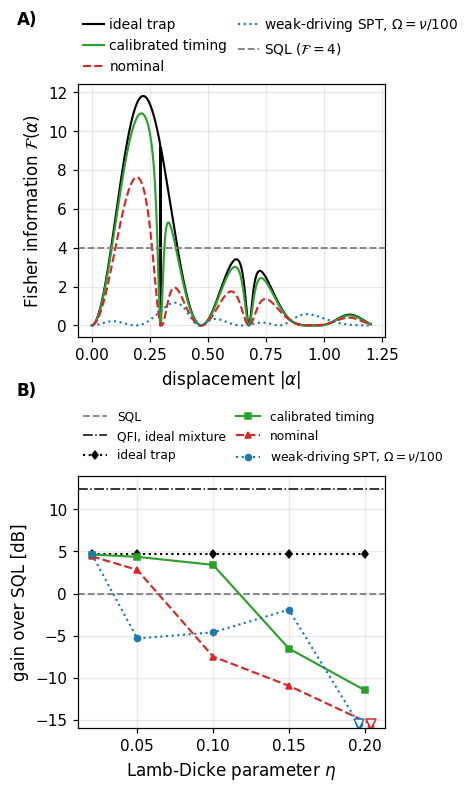

   saved -> figures\figure_6.pdf


In [26]:
# Panel A grid: the uniform grid plus dense points around every dip of the plotted curves. The ideal-trap
# curve has a needle-like zero (width ~1e-4) at the first root of L_n(|alpha|^2), where <n|D|n> vanishes
# and the detection probability nearly does too; a uniform grid would need ~1e5 points to resolve it.
pA = [PID, rows[FIG6_ETA_SHOW]["p_fix"], rows[FIG6_ETA_SHOW]["p_nom"], rows[FIG6_ETA_SHOW]["p_old"]]
F_at = lambda al, p: fisher_rows(p, *readout_rows([al], [n_meas])[n_meas])[0]
offs = np.logspace(-7, -2.5, 30)
extra = []
for p in pA:
    Fc = fisher_curve(p, n_meas)
    for k in np.where((Fc[1:-1] < Fc[:-2]) & (Fc[1:-1] < Fc[2:]))[0] + 1:
        a0 = minimize_scalar(lambda x: F_at(x, p), bounds=(FIG6_ALPHAS[k - 1], FIG6_ALPHAS[k + 1]),
                             method="bounded", options={"xatol": 1e-10}).x
        extra += [a0, *(a0 - offs), *(a0 + offs)]
extra = np.unique([x for x in extra if FIG6_ALPHAS[0] < x < FIG6_ALPHAS[-1]])
alA = np.concatenate([FIG6_ALPHAS, extra])
order = np.argsort(alA)
rows_extra = readout_rows(extra, [n_meas])[n_meas]
rowsA = tuple(np.concatenate([b, e])[order] for b, e in zip(ROWS6[n_meas], rows_extra))
alA = alA[order]
_dip = (alA > 0.25) & (alA < 0.35)
print(f"   panel A: {len(FIG6_ALPHAS)} uniform + {len(extra)} refinement points; "
      f"ideal-trap minimum near the first dip: {fisher_rows(PID, *rowsA)[_dip].min() if _dip.any() else np.nan:.2e}")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(3.6, 7.6), gridspec_kw={"hspace": 0.55})
a1.plot(alA, fisher_rows(PID, *rowsA), "k-", label="ideal trap")
a1.plot(alA, fisher_rows(rows[FIG6_ETA_SHOW]["p_fix"], *rowsA), "-",
        color="tab:green", label="calibrated timing")
a1.plot(alA, fisher_rows(rows[FIG6_ETA_SHOW]["p_nom"], *rowsA), "--",
        color="tab:red", label="nominal")
a1.plot(alA, fisher_rows(rows[FIG6_ETA_SHOW]["p_old"], *rowsA), ":",
        color="tab:blue", label=rf"weak-driving SPT, $\Omega=\nu/{int(round(1 / FIG6_OMEGA_OLD))}$")
a1.axhline(F_SQL, color="gray", ls="--", lw=1.2, label=r"SQL ($\mathcal{F}=4$)")
a1.set_xlabel(r"displacement $|\alpha|$")
a1.set_ylabel(r"Fisher information $\mathcal{F}(\alpha)$")
a1.grid(True, alpha=0.3)
a1.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.0, 1.02), ncol=2,
          borderaxespad=0.0, columnspacing=0.8, handlelength=1.5, handletextpad=0.4, fontsize=9)
a1.text(-0.2, 1.22, "A)", transform=a1.transAxes, va="bottom", fontweight="bold")
Y_LO, Y_HI = -16.0, 14.0
def _clip_plot(ax, x, y, fmt, dx=0.0, **kw):
    """Plot y, with points below the axis range drawn as open markers on the lower edge (shifted by dx
    so that clipped points of different curves do not hide each other)."""
    y = np.asarray(y, float); lo = y < Y_LO; x = np.asarray(x, float)
    xs = np.where(lo, x + dx, x)
    ax.plot(xs, np.maximum(y, Y_LO + 0.5), fmt, **kw)
    if lo.any():
        ax.plot(xs[lo], np.full(lo.sum(), Y_LO + 0.5), "v", color=kw.get("color", "k"), mfc="white", ms=6)
a2.axhline(0.0, color="gray", ls="--", lw=1.2, label="SQL")
a2.axhline(gdB(QFI_ID), color="k", ls="-.", lw=1.0, label="QFI, ideal mixture")
a2.plot(FIG6_ETAS, [gains[n_meas]] * len(FIG6_ETAS), "k:", marker="d", label="ideal trap")
_clip_plot(a2, FIG6_ETAS, [rows[e]["g_fix"] for e in FIG6_ETAS], "s-", color="tab:green", label="calibrated timing")
_clip_plot(a2, FIG6_ETAS, [rows[e]["g_nom"] for e in FIG6_ETAS], "^--", dx=0.004, color="tab:red", label="nominal")
_clip_plot(a2, FIG6_ETAS, [rows[e]["g_old"] for e in FIG6_ETAS], "o:", dx=-0.004, color="tab:blue",
           label=rf"weak-driving SPT, $\Omega=\nu/{int(round(1 / FIG6_OMEGA_OLD))}$")
a2.set_ylim(Y_LO, Y_HI)
a2.set_xlabel(r"Lamb-Dicke parameter $\eta$")
a2.set_ylabel("gain over SQL [dB]")
a2.grid(True, alpha=0.3)
a2.legend(frameon=False, fontsize=8, ncol=2, loc="lower left", bbox_to_anchor=(0.0, 1.02), borderaxespad=0.0,
           columnspacing=0.8)
a2.text(-0.2, 1.3, "B)", transform=a2.transAxes, va="bottom", fontweight="bold")
save(fig, "figure_6.pdf")

## Additional figures (not in the paper)

The next three sections draw figures that are not in the paper. They hold the evidence behind statements of its text, and their results feed Figure 7, which is therefore drawn last.

## Additional figure S1: pulse shaping

The paper states in one sentence (Sec. III B) that shaping the $X$ pulse does not improve on the square pulse, and that small modulations around $\Omega=\nu$ gain at most 12%. This figure shows it.

- **(A)** Smooth amplitude envelopes of the $X$ pulse, area-matched at fixed duration: Hann, Blackman, flat-top. Two variants that keep the peak $\Omega=\nu$ are also shown:
  - a plateau with short ramps;
  - a Hann or flat-top envelope with a detuning chirp $\Delta(t)=\sqrt{\nu^2-\Omega(t)^2}$, which keeps the dressed splitting at $\nu$ (referee minor comment 8).

  None of them reaches the calibrated timing (green).
- **(B)** Time-dependent Rabi-frequency offsets $\delta\Omega(t)$ (constant, bump, edges, ramp), with the amplitude optimised for each $\eta$.

[fig S1] pulse shaping


   square          0.05:0.079  0.075:0.108  0.1:0.260  0.125:0.336  0.15:0.288  0.175:0.383  0.2:0.513


   Hann            0.05:0.727  0.075:0.853  0.1:0.816  0.125:0.836  0.15:0.845  0.175:0.822  0.2:0.752


   Blackman        0.05:0.689  0.075:0.892  0.1:0.856  0.125:0.845  0.15:0.746  0.175:0.849  0.2:0.802


   flat-top        0.05:0.698  0.075:0.786  0.1:0.869  0.125:0.656  0.15:0.717  0.175:0.800  0.2:0.823


   plateau         0.05:0.533  0.075:0.703  0.1:0.562  0.125:0.476  0.15:0.547  0.175:0.566  0.2:0.648


... (4 outputs left out)

   const           0.05:0.079  0.1:0.260  0.15:0.288  0.2:0.481


   bump            0.05:0.079  0.1:0.227  0.15:0.277  0.2:0.486


   edges           0.05:0.070  0.1:0.232  0.15:0.278  0.2:0.478


   ramp            0.05:0.079  0.1:0.260  0.15:0.288  0.2:0.493


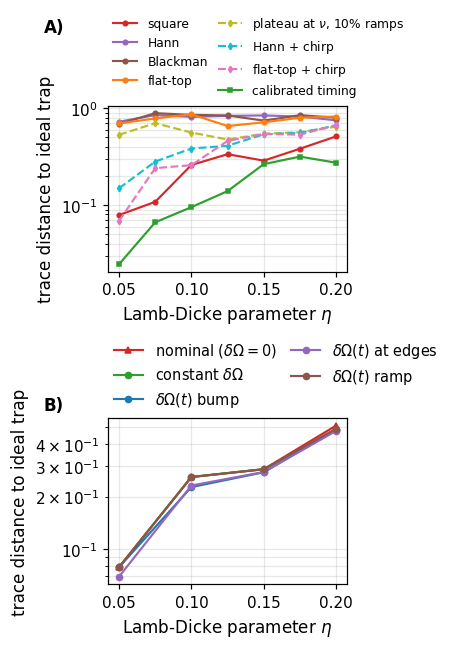

   saved -> figures\figure_S1_pulse_shaping.pdf


In [27]:
# Additional figure S1 (not in the paper): pulse shaping (area-matched amplitude envelopes, plateau and chirped envelopes, small
# Rabi-frequency profiles)
print("[fig S1] pulse shaping")
envelopes = {k: ENVELOPES[k] for k in ("square", "Hann", "Blackman", "flat-top")}
env_col = {"square": "tab:red", "Hann": "tab:purple", "Blackman": "tab:brown", "flat-top": "tab:orange"}
tc = np.linspace(0, 1, M_CHIRP)
profiles = {
    "const": np.ones(M_CHIRP),
    "bump": np.exp(-((tc - 0.5) / 0.2) ** 2),
    "edges": np.exp(-(tc / 0.2) ** 2) + np.exp(-((tc - 1) / 0.2) ** 2),
    "ramp": 2 * tc - 1,
}
prof_col = {"const": "tab:green", "bump": "tab:blue", "edges": "tab:purple", "ramp": "tab:brown"}
prof_lbl = {"const": r"constant $\delta\Omega$", "bump": r"$\delta\Omega(t)$ bump",
            "edges": r"$\delta\Omega(t)$ at edges", "ramp": r"$\delta\Omega(t)$ ramp"}
td_env = {name: [cached(("fig7a", name, e), lambda: td_new(e, envelope=env))
                 for e in FIG7_ETAS_SHAPE] for name, env in envelopes.items()}
# referee minor 8: plateau at Omega = nu with short ramps; detuning chirp keeping sqrt(Omega^2 + Delta^2) = nu
smooth = {"plateau": ("plateau", "plateau", "tab:olive", r"plateau at $\nu$, 10% ramps"),
          "chirp Hann": ("Hann-smooth", "chirp", "tab:cyan", r"Hann $+$ chirp"),
          "chirp flat-top": ("flat-top-smooth", "chirp", "tab:pink", r"flat-top $+$ chirp")}
_sm_specs = [dict(eta=_r(e), env=env, env_mode=mode, model="ref") for env, mode, _, _ in smooth.values()
             for e in FIG7_ETAS_SHAPE]
_v = run_sims(f"fig7_smooth_M{M_SMOOTH}", _sm_specs, "fig7 plateau/chirp")
td_smooth = {k: _v[i * len(FIG7_ETAS_SHAPE):(i + 1) * len(FIG7_ETAS_SHAPE)] for i, k in enumerate(smooth)}
td_ref = [calib[_r(e)]["td"] for e in FIG7_ETAS_SHAPE]          # timing calibration from Figure 5
td_chirp_nom = [cached(("fig7nom", e), lambda: td_new(e)) for e in FIG7_ETAS_CHIRP]
td_chirp = {pr: [cached(("fig7b_rabi", pr, e, FIG7_AMPS.max()), lambda: min(td_new(e, dOm_profile=A * shape)
                                                      for A in FIG7_AMPS))
                 for e in FIG7_ETAS_CHIRP] for pr, shape in profiles.items()}
for name in envelopes:
    print(f"   {name:15s} " + "  ".join(f"{e:g}:{v:.3f}" for e, v in zip(FIG7_ETAS_SHAPE, td_env[name])))
for name in smooth:
    print(f"   {name:15s} " + "  ".join(f"{e:g}:{v:.3f}" for e, v in zip(FIG7_ETAS_SHAPE, td_smooth[name])))
print("   calibrated      " + "  ".join(f"{e:g}:{v:.3f}" for e, v in zip(FIG7_ETAS_SHAPE, td_ref)))
print("   nominal         " + "  ".join(f"{e:g}:{v:.3f}" for e, v in zip(FIG7_ETAS_CHIRP, td_chirp_nom)))
for pr in profiles:
    print(f"   {pr:15s} " + "  ".join(f"{e:g}:{v:.3f}" for e, v in zip(FIG7_ETAS_CHIRP, td_chirp[pr])))
fig, (a1, a2) = plt.subplots(2, 1, figsize=(3.6, 6.2))
for name in envelopes:
    a1.plot(FIG7_ETAS_SHAPE, td_env[name], "o-", color=env_col[name], ms=3, label=name)
for name, (_, _, col, lab) in smooth.items():
    a1.plot(FIG7_ETAS_SHAPE, td_smooth[name], "d--", color=col, ms=3, label=lab)
a1.plot(FIG7_ETAS_SHAPE, td_ref, "s-", color="tab:green", ms=3, label="calibrated timing")
a1.set_xlabel(r"Lamb-Dicke parameter $\eta$")
a1.set_ylabel("trace distance to ideal trap")
a1.set_yscale("log"); a1.grid(True, which="both", alpha=0.3)
a1.legend(frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0.0, 1.02),
          borderaxespad=0.0, columnspacing=0.8, fontsize=8)
a1.text(-0.27, 1.42, "A)", transform=a1.transAxes, va="bottom", fontweight="bold")
a2.plot(FIG7_ETAS_CHIRP, td_chirp_nom, "^-", color="tab:red", label=r"nominal ($\delta\Omega=0$)")
for pr in profiles:
    a2.plot(FIG7_ETAS_CHIRP, td_chirp[pr], "o-", color=prof_col[pr], label=prof_lbl[pr])
a2.set_xlabel(r"Lamb-Dicke parameter $\eta$")
a2.set_ylabel("trace distance to ideal trap")
a2.set_yscale("log"); a2.grid(True, which="both", alpha=0.3)
a2.legend(frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0.0, 1.02),
          borderaxespad=0.0, columnspacing=1.0)
a2.text(-0.27, 1.02, "B)", transform=a2.transAxes, va="bottom", fontweight="bold")
fig.tight_layout()
save(fig, "figure_S1_pulse_shaping.pdf")

## Additional figure S2: tolerances

Panel (A) of this figure is panel (B) of Figure 7 of the paper; panel (B) adds the laser detuning quoted in Sec. IV ($\Delta=0.05\nu$ raises the error only from 0.025 to 0.029).

At $\eta=0.05$, for the calibrated timing and the nominal sequence, the sequence is designed for $\nu=\Omega=1$. The cell applies static relative errors to three parameters:
- the Rabi frequency $\Omega$;
- the pulse length;
- the true trap frequency $\nu$.

It also applies a laser detuning $\Delta$. The printed tolerance windows are the ranges of relative error in which the calibrated error stays below 1.25, 1.5 and 2 times its optimum.

The narrow peaks of the pulse-length and trap-frequency curves, near $-0.3\%$ (calibrated) and $-0.05\%$ (nominal), are the cycle-period resonance of Fig. 5.

In [28]:
# Robustness at eta_ref (referee M5): static calibration errors of Omega, of the pulse length and of the
# trap frequency, laser detuning, Rabi-frequency noise and motional heating, for the calibrated timing
# (solid) and the nominal sequence (dashed). The sequence is designed for nu = 1, Omega = 1.
print(f"[robustness] calibration errors at eta = {ETA_REF}")
e = _r(ETA_REF); c = calib[e]
cal_kw = dict(f=_r(c["f"]), delay=_r(c["delay"]), dOm=_r(c["dOm"]))
nom_kw = dict(f=1.0, delay=0.0, dOm=0.0)
rob_specs = []
for kw in (cal_kw, nom_kw):
    for x in ROB_EPS:
        rob_specs += [dict(eta=e, model="ref", **{**kw, "dOm": _r(kw["dOm"] + x)}),
                      dict(eta=e, model="ref", **{**kw, "f": _r(kw["f"] * (1 + x))}),
                      dict(eta=e, model="ref", nut=_r(1 + x), **kw)]
    rob_specs += [dict(eta=e, model="ref", Delta=_r(D), **kw) for D in ROB_DELTAS]
_v = np.array(run_sims("rob", rob_specs, "robustness"))
nE, nD_ = len(ROB_EPS), len(ROB_DELTAS)
blk = 3 * nE + nD_
rob = {}
for b, nm in enumerate(("cal", "nom")):
    v = _v[b * blk:(b + 1) * blk]
    rob[nm] = dict(Om=v[0:3 * nE:3], f=v[1:3 * nE:3], nu=v[2:3 * nE:3], Delta=v[3 * nE:])
    print(f"   {nm}: relative error  " + "  ".join(f"{x:+.4f}" for x in ROB_EPS))
    for k in ("Om", "f", "nu"):
        print(f"      {k:5s}            " + "  ".join(f"{x:.4f}" for x in rob[nm][k]))
    print("      detuning " + "  ".join(f"{D:g}:{x:.4f}" for D, x in zip(ROB_DELTAS, rob[nm]["Delta"])))


def _window(xs, v, thr):
    """Contiguous range of xs around 0 in which v <= thr (grid resolution)."""
    i0 = int(np.argmin(np.abs(xs)))
    if v[i0] > thr:
        return np.nan, np.nan
    lo = hi = i0
    while lo > 0 and v[lo - 1] <= thr:
        lo -= 1
    while hi < len(xs) - 1 and v[hi + 1] <= thr:
        hi += 1
    return xs[lo], xs[hi]


for fac in (1.25, 1.5, 2.0):
    thr = fac * c["td"]
    parts = []
    for k in ("Om", "f", "nu"):
        lo, hi = _window(ROB_EPS, rob["cal"][k], thr)
        s = f"{k} [{lo * 100:+.2f}%, {hi * 100:+.2f}%]"
        if k == "f" and not np.isnan(lo):
            s += f" = [{lo * c['f'] * tau_of(e):+.3f}, {hi * c['f'] * tau_of(e):+.3f}]/nu of pulse time"
        parts.append(s)
    print(f"   tolerance window (calibrated TD <= {fac:g} x {c['td']:.4f}): " + ";  ".join(parts))

[robustness] calibration errors at eta = 0.05


   cal: relative error  -0.0200  -0.0175  -0.0150  -0.0125  -0.0100  -0.0075  -0.0050  -0.0040  -0.0035  -0.0030  -0.0025  -0.0020  -0.0015  -0.0010  -0.0005  +0.0000  +0.0005  +0.0010  +0.0015  +0.0020  +0.0025  +0.0030  +0.0035  +0.0040  +0.0050  +0.0075  +0.0100  +0.0125  +0.0150  +0.0175  +0.0200


      Om               0.3537  0.2811  0.2056  0.1323  0.0737  0.0374  0.0249  0.0239  0.0244  0.0246  0.0245  0.0247  0.0245  0.0246  0.0246  0.0245  0.0248  0.0247  0.0250  0.0252  0.0262  0.0275  0.0291  0.0311  0.0362  0.0600  0.1207  0.2130  0.3268  0.4463  0.5593


      f                0.3958  0.3364  0.2909  0.2421  0.1847  0.1222  0.0777  0.0961  0.1294  0.1239  0.0862  0.0580  0.0415  0.0318  0.0265  0.0245  0.0248  0.0275  0.0329  0.0401  0.0486  0.0581  0.0684  0.0794  0.1024  0.1614  0.2176  0.2730  0.3427  0.4181  0.4837


      nu               0.3483  0.3080  0.2575  0.1931  0.1275  0.0748  0.0578  0.0828  0.1191  0.1188  0.0828  0.0552  0.0396  0.0309  0.0263  0.0245  0.0247  0.0262  0.0301  0.0356  0.0422  0.0497  0.0580  0.0670  0.0866  0.1497  0.2318  0.3583  0.5133  0.6648  0.7761


      detuning 0:0.0245  0.01:0.0250  0.02:0.0257  0.05:0.0285  0.1:0.0465  0.2:0.3683


... (4 outputs left out)

      detuning 0:0.0789  0.01:0.0801  0.02:0.0823  0.05:0.0959  0.1:0.1465  0.2:0.4564


   tolerance window (calibrated TD <= 1.25 x 0.0245): Om [-0.50%, +0.35%];  f [-0.05%, +0.10%] = [-0.063, +0.126]/nu of pulse time;  nu [-0.05%, +0.15%]


   tolerance window (calibrated TD <= 1.5 x 0.0245): Om [-0.50%, +0.50%];  f [-0.10%, +0.15%] = [-0.126, +0.189]/nu of pulse time;  nu [-0.10%, +0.20%]


   tolerance window (calibrated TD <= 2 x 0.0245): Om [-0.75%, +0.50%];  f [-0.15%, +0.25%] = [-0.189, +0.315]/nu of pulse time;  nu [-0.15%, +0.25%]


**Noise and heating** (printed only):
- **Rabi-frequency noise** of 0.2–1% rms, either static over a preparation or redrawn every cycle.
- **Motional heating** at $1$–$10^4$ quanta/s. The trace distance is recorded after every cycle, so the best stopping point can be read off. A level $n$ leaves at a rate $\gamma(2n+1)$, so heating is very damaging for Fock mixtures.

In [29]:
noise_specs = [dict(eta=e, model="ref", noise=(_r(s), kind), **cal_kw) for s in ROB_NOISE for kind in ("static", "cycle")]
g_of = lambda r: r / (2 * np.pi * NU_HZ)                           # quanta/s -> quanta per unit time 1/nu
_v = run_sims("rob", noise_specs, "robustness noise")
for s, v in zip(noise_specs, _v):
    print(f"   Omega noise {s['noise'][0] * 100:.1f}% rms ({s['noise'][1]:6s}): TD {v:.4f}  (no noise {c['td']:.4f})")
# heating: trace distance after every cycle, so that the best stopping point can be read off
heat_specs = [dict(eta=e, model="ref", heat=_r(g_of(r)), out="hist", **cal_kw) for r in [0.0] + list(ROB_HEAT)]
_tcyc = t_cycle_new(e, c["f"], None, c["delay"])
for r, h in zip([0.0] + list(ROB_HEAT), run_sims("rob_hist", heat_specs, "robustness heating")):
    k = int(np.argmin(h))
    print(f"   heating {r:g} quanta/s ({r * R * _tcyc / (2 * np.pi * NU_HZ):.3g} quanta over {R} cycles): "
          f"TD after {R} cycles {h[-1]:.4f}; after 40 cycles {h[min(40, len(h) - 1)]:.4f}; "
          f"best {h[k]:.4f} after {k} cycles ({to_ms(k * _tcyc):.2f} ms)")

   Omega noise 0.2% rms (static): TD 0.0247  (no noise 0.0245)


   Omega noise 0.2% rms (cycle ): TD 0.0247  (no noise 0.0245)


   Omega noise 0.5% rms (static): TD 0.0325  (no noise 0.0245)


   Omega noise 0.5% rms (cycle ): TD 0.0326  (no noise 0.0245)


   Omega noise 1.0% rms (static): TD 0.1087  (no noise 0.0245)


   Omega noise 1.0% rms (cycle ): TD 0.1615  (no noise 0.0245)


... (2 outputs left out)

   heating 10 quanta/s (0.0161 quanta over 80 cycles): TD after 80 cycles 0.0757; after 40 cycles 0.0676; best 0.0673 after 45 cycles (0.90 ms)


   heating 100 quanta/s (0.161 quanta over 80 cycles): TD after 80 cycles 0.2704; after 40 cycles 0.2231; best 0.2064 after 20 cycles (0.40 ms)


   heating 1000 quanta/s (1.61 quanta over 80 cycles): TD after 80 cycles 0.6350; after 40 cycles 0.5500; best 0.4405 after 7 cycles (0.14 ms)


   heating 10000 quanta/s (16.1 quanta over 80 cycles): TD after 80 cycles 0.6424; after 40 cycles 0.6307; best 0.6128 after 20 cycles (0.40 ms)


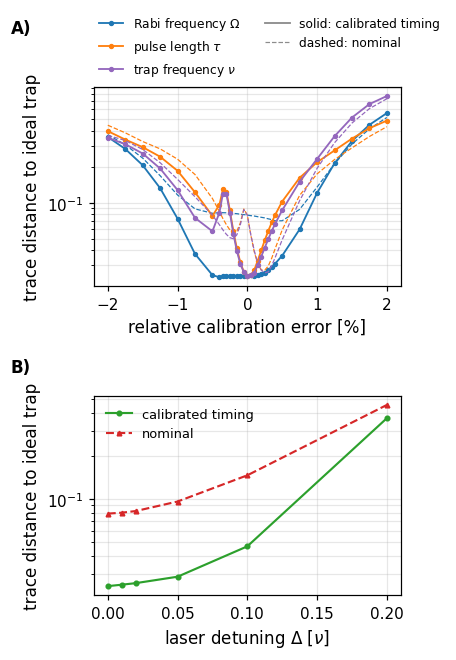

   saved -> figures\figure_S2_tolerances.pdf


In [30]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(3.6, 6.0), gridspec_kw={"hspace": 0.55})
for k, col, lab in (("Om", "tab:blue", r"Rabi frequency $\Omega$"), ("f", "tab:orange", r"pulse length $\tau$"),
                    ("nu", "tab:purple", r"trap frequency $\nu$")):
    a1.plot(ROB_EPS * 100, rob["cal"][k], "o-", color=col, ms=2.5, lw=1.2, label=lab)
    a1.plot(ROB_EPS * 100, rob["nom"][k], "--", color=col, lw=0.8)
a1.plot([], [], "-", color="0.55", lw=1.2, label="solid: calibrated timing")
a1.plot([], [], "--", color="0.55", lw=0.8, label="dashed: nominal")
a1.set_xlabel("relative calibration error [%]")
a1.set_ylabel("trace distance to ideal trap")
a1.set_yscale("log"); a1.grid(True, which="both", alpha=0.3)
a1.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.0, 1.02), borderaxespad=0.0, ncol=2, fontsize=8)
a1.text(-0.27, 1.25, "A)", transform=a1.transAxes, va="bottom", fontweight="bold")
a2.plot(ROB_DELTAS, rob["cal"]["Delta"], "o-", color="tab:green", ms=3, label="calibrated timing")
a2.plot(ROB_DELTAS, rob["nom"]["Delta"], "^--", color="tab:red", ms=3, label="nominal")
a2.set_xlabel(r"laser detuning $\Delta$ $[\nu]$")
a2.set_ylabel("trace distance to ideal trap")
a2.set_yscale("log"); a2.grid(True, which="both", alpha=0.3)
a2.legend(frameon=False, fontsize=8.5)
a2.text(-0.27, 1.1, "B)", transform=a2.transAxes, va="bottom", fontweight="bold")
save(fig, "figure_S2_tolerances.pdf")

## Additional figure S3: the $^{40}$Ca$^+$ models in full

Panel (A) of this figure is panel (A) of Figure 7 of the paper. The cells also print the numbers quoted in Sec. IV: the dependence on the quench rate, the gains and the preparation time.

**Models.** Each pulse and reset model has its own timing calibration:
- the reference model;
- `Ca_Oy2` and `Ca_Oy1`: realistic $Y$ pulses ($\Omega_Y=2\nu$, $\nu$) and the 854-nm quench reset.

**Panels.**
- **(A)** Trace distance against $\eta$, calibrated (solid) and nominal (dashed). The dotted line is the 729-nm beam along the axis, $\eta=0.097$.
- **(B)** Trace distance against $\Omega_Y$ at $\eta=0.05$, for the fast reset and for the quench reset.

**Printed only:**
- the dependence on the quench rate;
- the single-level Fisher gain, the QFI and the preparation time of the $^{40}$Ca$^+$ models;
- a convergence check of the reset quadrature.

In [31]:
# 40Ca+ implementation (referee M4): realistic Y pulses (Omega_Y = nu, 2 nu) and an 854-nm quench reset
# (Gamma_eff = 3 nu, 393-nm emission recoil, 854-nm absorption kick, decay back to D), each with its own
# timing calibration; and the dependence on Omega_Y and on the quench rate at eta_ref.
print("[implementation] 40Ca+: realistic Y pulses and quench reset")
for oy in IMPL_OY:
    MODELS[f"fast_Oy{oy:g}"] = dict(MODEL_REF, Oy=oy * nu)
    MODELS[f"Ca_Oy{oy:g}"] = dict(Oy=oy * nu, **CA_RESET)
for G in IMPL_GAMMAS:
    MODELS[f"Ca_Oy2_G{G:g}"] = dict(Oy=2.0 * nu, **{**CA_RESET, "G": G * nu, "Tr": 20.0 / G})
cal_impl = {"ref": calibrate_many(ETA_IMPL, "ref", "impl ref")}
for mdl in ("Ca_Oy2", "Ca_Oy1"):
    cal_impl[mdl] = calibrate_many(ETA_IMPL, mdl, f"impl {mdl}")
cal_oy = {}
for oy in IMPL_OY:
    for rs in ("fast", "Ca"):
        cal_oy[(oy, rs)] = calibrate_many([ETA_REF], f"{rs}_Oy{oy:g}", f"impl Oy={oy:g} {rs} reset")[_r(ETA_REF)]
cal_G = {G: calibrate_many([ETA_REF], f"Ca_Oy2_G{G:g}", f"impl Gamma={G:g}")[_r(ETA_REF)] for G in IMPL_GAMMAS}
for mdl, cc in cal_impl.items():
    print(f"   model {mdl}: {MODELS[mdl]}")
    for e_ in ETA_IMPL:
        r_ = cc[_r(e_)]
        print(f"      eta={e_:<7g} nominal {r_['nom']:.4f}  f only {r_['f_only'][0]:.4f}  f+delay {r_['joint'][0]:.4f} "
              f"(lengthening {(r_['joint'][1] - 1) * tau_of(e_):+.3f}/nu, delay {r_['joint'][2]:.3f}/nu)")
for (oy, rs), r_ in cal_oy.items():
    print(f"   eta={ETA_REF} Omega_Y={oy:g} nu, {rs:4s} reset: nominal {r_['nom']:.4f}  f+delay {r_['joint'][0]:.4f}")
for G, r_ in cal_G.items():
    print(f"   eta={ETA_REF} Omega_Y=2 nu, Ca reset with Gamma_eff={G:g} nu: nominal {r_['nom']:.4f}  f+delay {r_['joint'][0]:.4f}")

[implementation] 40Ca+: realistic Y pulses and quench reset


   model ref: {'Oy': 100.0, 'G': 1000.0, 'Tr': 0.02, 'em_rel': 1.0, 'em_abs': None, 'abs_rel': 0.0, 'p_rep': 0.0}


      eta=0.02    nominal 0.0121  f only 0.0055  f+delay 0.0049 (lengthening +0.188/nu, delay 0.150/nu)


      eta=0.03    nominal 0.0189  f only 0.0141  f+delay 0.0118 (lengthening +0.251/nu, delay 0.543/nu)


      eta=0.04    nominal 0.0500  f only 0.0179  f+delay 0.0158 (lengthening +0.251/nu, delay 0.100/nu)


      eta=0.05    nominal 0.0789  f only 0.0274  f+delay 0.0245 (lengthening +0.251/nu, delay 0.100/nu)


... (33 outputs left out)

   eta=0.05 Omega_Y=100 nu, fast reset: nominal 0.0789  f+delay 0.0245


   eta=0.05 Omega_Y=100 nu, Ca   reset: nominal 0.0811  f+delay 0.0523


   eta=0.05 Omega_Y=2 nu, Ca reset with Gamma_eff=1 nu: nominal 0.1500  f+delay 0.0593


   eta=0.05 Omega_Y=2 nu, Ca reset with Gamma_eff=10 nu: nominal 0.1401  f+delay 0.0597


In [32]:
# metrology and preparation time of the 40Ca+ models with their calibrated timing
_met_specs, _met_lab = [], []
for mdl in ("ref", "Ca_Oy2", "Ca_Oy1"):
    for e_ in [x for x in ETA_IMPL if _r(x) in (_r(ETA_REF), _r(round(float(ETA_CA_AXIAL), 4)))]:
        r_ = cal_impl[mdl][_r(e_)]
        _met_specs.append(dict(eta=_r(e_), f=_r(r_["joint"][1]), delay=_r(r_["joint"][2]), model=mdl, out="p"))
        _met_lab.append((mdl, e_, r_["joint"][1], r_["joint"][2]))
for (mdl, e_, f_, d_), (td_, p_) in zip(_met_lab, run_sims("impl_met", _met_specs, "impl metrology")):
    tc = t_cycle_new(e_, f_, mdl, d_)
    print(f"   {mdl:7s} eta={e_:.4f} calibrated: TD {td_:.4f}; single-level gain (n={n_meas}) "
          f"{gdB(fisher_curve(p_, n_meas).max()):+.2f} dB; QFI {gdB(qfi_pop(p_)):+.2f} dB; "
          f"cycle {tc:.1f}/nu, {R} cycles = {to_ms(R * tc):.2f} ms")

   ref     eta=0.0500 calibrated: TD 0.0245; single-level gain (n=16) +4.36 dB; QFI +11.98 dB; cycle 126.1/nu, 80 cycles = 1.61 ms


   ref     eta=0.0969 calibrated: TD 0.1091; single-level gain (n=16) +3.07 dB; QFI +10.54 dB; cycle 65.7/nu, 80 cycles = 0.84 ms


   Ca_Oy2  eta=0.0500 calibrated: TD 0.0602; single-level gain (n=16) +3.71 dB; QFI +11.37 dB; cycle 137.7/nu, 80 cycles = 1.75 ms


   Ca_Oy2  eta=0.0969 calibrated: TD 0.1494; single-level gain (n=16) +0.95 dB; QFI +9.63 dB; cycle 77.9/nu, 80 cycles = 0.99 ms


   Ca_Oy1  eta=0.0500 calibrated: TD 0.0679; single-level gain (n=16) +3.61 dB; QFI +11.23 dB; cycle 137.5/nu, 80 cycles = 1.75 ms


   Ca_Oy1  eta=0.0969 calibrated: TD 0.1728; single-level gain (n=16) -0.06 dB; QFI +9.21 dB; cycle 77.8/nu, 80 cycles = 0.99 ms


In [33]:
# quadrature check of the slow reset
_chk =[dict(eta=_r(ETA_REF), model="Ca_Oy2")]
_v0 = run_sims("impl_chk", _chk)[0]
_save_nodes = RESET_NODES_SLOW; RESET_NODES_SLOW = int(1.5 * RESET_NODES_SLOW); _RESETS.clear()
_v1 = sim(_chk[0]); RESET_NODES_SLOW = _save_nodes; _RESETS.clear()
print(f"   slow-reset quadrature check (Ca_Oy2, eta={ETA_REF}, nominal): {_save_nodes} nodes {_v0:.5f}, "
      f"{int(1.5 * _save_nodes)} nodes {_v1:.5f}")

   slow-reset quadrature check (Ca_Oy2, eta=0.05, nominal): 120 nodes 0.14023, 180 nodes 0.14023


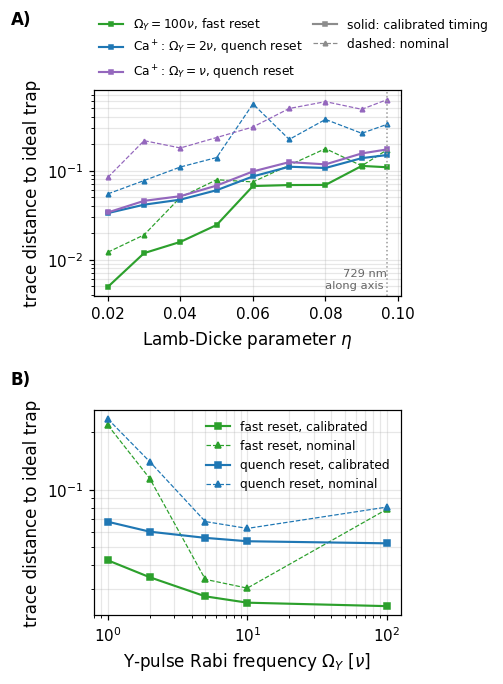

   saved -> figures\figure_S3_implementation.pdf


In [34]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(3.6, 6.2), gridspec_kw={"hspace": 0.55})
for mdl, col, lab in (("ref", "tab:green", r"$\Omega_Y=100\nu$, fast reset"),
                      ("Ca_Oy2", "tab:blue", r"Ca$^+$: $\Omega_Y=2\nu$, quench reset"),
                      ("Ca_Oy1", "tab:purple", r"Ca$^+$: $\Omega_Y=\nu$, quench reset")):
    cc = cal_impl[mdl]
    a1.plot(ETA_IMPL, [cc[_r(x)]["joint"][0] for x in ETA_IMPL], "s-", color=col, ms=3, label=lab)
    a1.plot(ETA_IMPL, [cc[_r(x)]["nom"] for x in ETA_IMPL], "^--", color=col, ms=3, lw=0.8)
a1.plot([], [], "s-", color="0.55", ms=3, label="solid: calibrated timing")
a1.plot([], [], "^--", color="0.55", ms=3, lw=0.8, label="dashed: nominal")
a1.axvline(ETA_CA_AXIAL, color="0.6", ls=":", lw=1)
a1.text(ETA_CA_AXIAL, 0.03, "729 nm\nalong axis ", transform=a1.get_xaxis_transform(), fontsize=7.5, va="bottom",
        ha="right", color="0.4")
a1.set_xlabel(r"Lamb-Dicke parameter $\eta$")
a1.set_ylabel("trace distance to ideal trap")
a1.set_yscale("log"); a1.grid(True, which="both", alpha=0.3)
a1.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.0, 1.02), borderaxespad=0.0, fontsize=8, ncol=2,
          columnspacing=0.8)
a1.text(-0.27, 1.3, "A)", transform=a1.transAxes, va="bottom", fontweight="bold")
for rs, col, lab in (("fast", "tab:green", "fast reset"), ("Ca", "tab:blue", "quench reset")):
    a2.plot(IMPL_OY, [cal_oy[(oy, rs)]["joint"][0] for oy in IMPL_OY], "s-", color=col, ms=4, label=f"{lab}, calibrated")
    a2.plot(IMPL_OY, [cal_oy[(oy, rs)]["nom"] for oy in IMPL_OY], "^--", color=col, ms=4, lw=0.8, label=f"{lab}, nominal")
a2.set_xscale("log"); a2.set_yscale("log")
a2.set_xlabel(r"Y-pulse Rabi frequency $\Omega_Y$ $[\nu]$")
a2.set_ylabel("trace distance to ideal trap")
a2.grid(True, which="both", alpha=0.3)
a2.legend(frameon=False, fontsize=8)
a2.text(-0.27, 1.1, "B)", transform=a2.transAxes, va="bottom", fontweight="bold")
save(fig, "figure_S3_implementation.pdf")

## Figure 7: implementation in $^{40}$Ca$^+$

Nothing new is computed here; the figure combines results of the two previous sections.
- **(A)** Trace distance against $\eta$ for the reference model and the two $^{40}$Ca$^+$ models, calibrated (solid squares) and not calibrated (dashed triangles), as in S3(A). The dotted line is the 729-nm beam along the axis, $\eta=0.097$.
- **(B)** Static relative errors of $\Omega$, of the pulse length and of the trap frequency at $\eta=0.05$, calibrated (solid) and not calibrated (dashed), as in S2(A). The narrow peaks are the cycle-period resonance of Fig. 5.

[fig 7] 40Ca+ implementation and calibration tolerances


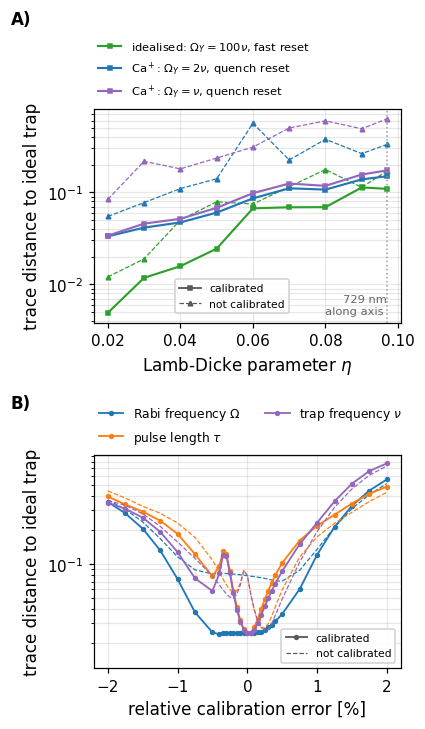

   saved -> figures\figure_ca.pdf


In [35]:
# Figure 7 of the paper: A) 40Ca+ versus eta (as figure_implementation A),
# B) static calibration errors at eta_ref (as figure_robustness A). Reuses the results computed above.
print("[fig 7] 40Ca+ implementation and calibration tolerances")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(3.6, 6.6), gridspec_kw={"hspace": 0.62})
for mdl, col, lab in (("ref", "tab:green", r"idealised: $\Omega_Y=100\nu$, fast reset"),
                      ("Ca_Oy2", "tab:blue", r"Ca$^+$: $\Omega_Y=2\nu$, quench reset"),
                      ("Ca_Oy1", "tab:purple", r"Ca$^+$: $\Omega_Y=\nu$, quench reset")):
    cc = cal_impl[mdl]
    a1.plot(ETA_IMPL, [cc[_r(x)]["joint"][0] for x in ETA_IMPL], "s-", color=col, ms=3, label=lab)
    a1.plot(ETA_IMPL, [cc[_r(x)]["nom"] for x in ETA_IMPL], "^--", color=col, ms=3, lw=0.8)
a1.axvline(ETA_CA_AXIAL, color="0.6", ls=":", lw=1)
a1.text(ETA_CA_AXIAL, 0.03, "729 nm\nalong axis ", transform=a1.get_xaxis_transform(), fontsize=7.5, va="bottom",
        ha="right", color="0.4")
a1.set_xlabel(r"Lamb-Dicke parameter $\eta$")
a1.set_ylabel("trace distance to ideal trap")
a1.set_yscale("log"); a1.grid(True, which="both", alpha=0.3)
a1.add_artist(a1.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.0, 1.02), borderaxespad=0.0,
                        fontsize=7.5, ncol=1))
a1.legend(handles=[Line2D([0], [0], color="0.35", ls="-", marker="s", ms=3, lw=1.2, label="calibrated"),
                   Line2D([0], [0], color="0.35", ls="--", marker="^", ms=3, lw=0.8, label="not calibrated")],
          loc="lower center", bbox_to_anchor=(0.45, 0.02), fontsize=7, framealpha=0.9)   # line-style key
a1.text(-0.27, 1.38, "A)", transform=a1.transAxes, va="bottom", fontweight="bold")
for k, col, lab in (("Om", "tab:blue", r"Rabi frequency $\Omega$"), ("f", "tab:orange", r"pulse length $\tau$"),
                    ("nu", "tab:purple", r"trap frequency $\nu$")):
    a2.plot(ROB_EPS * 100, rob["cal"][k], "o-", color=col, ms=2.5, lw=1.2, label=lab)
    a2.plot(ROB_EPS * 100, rob["nom"][k], "--", color=col, lw=0.8)
a2.set_xlabel("relative calibration error [%]")
a2.set_ylabel("trace distance to ideal trap")
a2.set_yscale("log"); a2.grid(True, which="both", alpha=0.3)
a2.add_artist(a2.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.0, 1.02), borderaxespad=0.0, ncol=2,
                        fontsize=8))
a2.legend(handles=[Line2D([0], [0], color="0.35", ls="-", marker="o", ms=2.5, lw=1.2, label="calibrated"),
                   Line2D([0], [0], color="0.35", ls="--", lw=0.8, label="not calibrated")],
          loc="lower right", fontsize=7, framealpha=0.9)   # line-style key
a2.set_ylim(bottom=0.012)
a2.text(-0.27, 1.2, "B)", transform=a2.transAxes, va="bottom", fontweight="bold")
save(fig, "figure_ca.pdf")

In [36]:
print(f"All figures done in {(time.time() - T_START) / 60:.1f} min.")

All figures done in 1.6 min.
